# Talent Lifecycle Analytics: Predicting Candidate Joining Likelihood and Employee Attrition Risk using R

**Course:** 22ADC54N Introduction to Data Science Lab

**How to run:** Use a Jupyter/Colab runtime with **R**, then run the notebook from top to bottom. Upload `aug_train.csv` to the working directory / Files panel before running Part A. Part B downloads the IBM HR attrition dataset and therefore needs internet access unless you upload a local fallback copy.

**Important interpretation note:** The candidate dataset records whether a person is looking for a job change. It does **not** record actual offer acceptance or whether someone joined your company. The notebook keeps the project label `Likely_Join` for continuity, but it is only a proxy: `Yes` means the original target was `0` (not currently seeking a job change). Interpret hiring results as patterns associated with this proxy, not as a verified probability of joining.

`aug_test.csv` and `sample_submission.csv` are not needed for the internal train/test evaluation in this case study because `aug_test.csv` has no known outcomes. They are intended for generating competition-style predictions.


# 0. Setup and required packages

In [ ]:
options(repos = c(CRAN = "https://cloud.r-project.org"))

pkgs <- c("tidyverse", "caret", "lime",
          "arules", "scales", "corrplot")

to_install <- pkgs[
  !vapply(pkgs, requireNamespace, logical(1), quietly = TRUE)
]

if (length(to_install) > 0) {
  message("Installing required packages: ",
          paste(to_install, collapse = ", "))

  install.packages(to_install, dependencies = NA)
}

# Load packages
invisible(lapply(pkgs, library, character.only = TRUE))

set.seed(42)
options(repr.plot.width = 9, repr.plot.height = 5)
theme_set(theme_minimal(base_size = 12))

cat("Setup completed successfully.\n")

Installing required packages: caret, lime, arules, corrplot

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘future’, ‘future.apply’, ‘diagram’, ‘lava’, ‘prodlim’, ‘hardhat’, ‘ipred’, ‘e1071’, ‘foreach’, ‘recipes’, ‘reshape2’, ‘glmnet’


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: lattice


Attaching package: ‘caret’


The following object is masked from ‘package:purrr’:

    lift



Attaching package: ‘lime’


The follo

Setup completed successfully.


# PART A - CANDIDATE MODULE: Which profiles are less likely to be seeking a job change?

**Business question:** Which candidate profiles have a higher probability of being *not currently seeking a job change*, based on education, experience, employer details, and training history?

**Interpretation:** The source target does not record offer acceptance. In the code, `Likely_Join = Yes` is a project-friendly name for the proxy class “not currently seeking a job change.” Treat this as a candidate-stability indicator, not a confirmed joining prediction.

# 1. Dataset A: candidate profiles

In [ ]:
load_candidates <- function() {
  if (file.exists("aug_train.csv")) {
    message("Using local aug_train.csv")
    return(read.csv("aug_train.csv", stringsAsFactors = FALSE, na.strings = c("", "NA")))
  }
  message("aug_train.csv not found - loading 'jobchange' from CRAN package dlookr (same data)")
  if (!requireNamespace("dlookr", quietly = TRUE)) install.packages("dlookr")
  e <- new.env()
  data("jobchange", package = "dlookr", envir = e)
  as.data.frame(e$jobchange)
}

cand_raw <- load_candidates()

if ("city_dev_index" %in% names(cand_raw))
  names(cand_raw)[names(cand_raw) == "city_dev_index"] <- "city_development_index"
if ("job_chnge" %in% names(cand_raw) && !"target" %in% names(cand_raw))
  cand_raw$target <- ifelse(as.character(cand_raw$job_chnge) == "Yes", 1, 0)
cand_raw <- cand_raw %>% mutate(across(where(is.factor), as.character))

required_candidate_cols <- c("enrollee_id", "city_development_index", "gender",
  "relevent_experience", "enrolled_university", "education_level", "major_discipline",
  "experience", "company_size", "company_type", "last_new_job", "training_hours", "target")
missing_candidate_cols <- setdiff(required_candidate_cols, names(cand_raw))
if (length(missing_candidate_cols) > 0) {
  stop("Candidate dataset is missing required columns: ", paste(missing_candidate_cols, collapse = ", "),
       ". Please upload the expected aug_train.csv file.")
}

cat("Rows:", nrow(cand_raw), "| Columns:", ncol(cand_raw), "\n")
glimpse(cand_raw)

Using local aug_train.csv



Rows: 19158 | Columns: 14 
Rows: 19,158
Columns: 14
$ enrollee_id            <int> 8949, 29725, 11561, 33241, 666, 21651, 28806, 4…
$ city                   <chr> "city_103", "city_40", "city_21", "city_115", "…
$ city_development_index <dbl> 0.920, 0.776, 0.624, 0.789, 0.767, 0.764, 0.920…
$ gender                 <chr> "Male", "Male", NA, NA, "Male", NA, "Male", "Ma…
$ relevent_experience    <chr> "Has relevent experience", "No relevent experie…
$ enrolled_university    <chr> "no_enrollment", "no_enrollment", "Full time co…
$ education_level        <chr> "Graduate", "Graduate", "Graduate", "Graduate",…
$ major_discipline       <chr> "STEM", "STEM", "STEM", "Business Degree", "STE…
$ experience             <chr> ">20", "15", "5", "<1", ">20", "11", "5", "13",…
$ company_size           <chr> NA, "50-99", NA, NA, "50-99", NA, "50-99", "<10…
$ company_type           <chr> NA, "Pvt Ltd", NA, "Pvt Ltd", "Funded Startup",…
$ last_new_job           <chr> "1", ">4", "never", "never", "4", "1"

# 2. Data preparation (hiring data)

In [ ]:

# ============================================================
# HELPER FUNCTIONS FOR TALENT LIFECYCLE ANALYTICS
# Run this cell after package loading and before data cleaning.
# ============================================================

# 1. Group experience into common bands
make_exp_band <- function(years) {
  years <- suppressWarnings(as.numeric(as.character(years)))

  cut(
    years,
    breaks = c(-Inf, 2, 5, 10, 15, Inf),
    labels = c("0-2", "3-5", "6-10", "11-15", "16+"),
    right = TRUE,
    ordered_result = TRUE
  )
}


# 2. Plot outcome rates by category
rate_bar <- function(data, x_var, outcome_var,
                     positive_value, title, y_label) {

  plot_data <- data.frame(
    category = as.character(data[[x_var]]),
    outcome = as.character(data[[outcome_var]]),
    stringsAsFactors = FALSE
  ) %>%
    dplyr::group_by(category) %>%
    dplyr::summarise(
      n = dplyr::n(),
      rate = mean(outcome == positive_value, na.rm = TRUE),
      .groups = "drop"
    ) %>%
    dplyr::arrange(rate)

  ggplot2::ggplot(
    plot_data,
    ggplot2::aes(x = reorder(category, rate), y = rate)
  ) +
    ggplot2::geom_col(fill = "#756bb1") +
    ggplot2::geom_text(
      ggplot2::aes(
        label = paste0(
          scales::percent(rate, accuracy = 0.1),
          " (n=", n, ")"
        )
      ),
      hjust = -0.08,
      size = 3
    ) +
    ggplot2::coord_flip() +
    ggplot2::scale_y_continuous(
      labels = scales::percent,
      expand = ggplot2::expansion(mult = c(0, 0.22))
    ) +
    ggplot2::labs(
      title = title,
      x = NULL,
      y = y_label
    ) +
    ggplot2::theme_minimal(base_size = 11)
}


# 3. Calculate AUC from predicted probabilities
auc_fn <- function(prob, truth) {
  truth <- as.character(truth)

  keep <- is.finite(prob) & !is.na(truth)
  prob <- prob[keep]
  is_yes <- truth[keep] == "Yes"

  n_yes <- sum(is_yes)
  n_no <- sum(!is_yes)

  if (n_yes == 0 || n_no == 0) {
    return(NA_real_)
  }

  ranks <- rank(prob, ties.method = "average")

  as.numeric(
    (sum(ranks[is_yes]) - n_yes * (n_yes + 1) / 2) /
      (n_yes * n_no)
  )
}


# 4. Find the probability threshold using Youden's J
youden_threshold <- function(prob, truth) {
  truth <- as.character(truth)

  keep <- is.finite(prob) & !is.na(truth)
  prob <- prob[keep]
  is_yes <- truth[keep] == "Yes"

  n_yes <- sum(is_yes)
  n_no <- sum(!is_yes)

  if (n_yes == 0 || n_no == 0) {
    warning("Only one outcome class is present; using threshold 0.5.")
    return(0.5)
  }

  thresholds <- seq(0, 1, by = 0.005)

  sensitivity <- vapply(
    thresholds,
    function(thr) sum(prob >= thr & is_yes) / n_yes,
    numeric(1)
  )

  specificity <- vapply(
    thresholds,
    function(thr) sum(prob < thr & !is_yes) / n_no,
    numeric(1)
  )

  thresholds[
    which.max(sensitivity + specificity - 1)
  ]
}


# 5. Generate ROC curve coordinates
roc_points <- function(prob, truth) {
  truth <- as.character(truth)

  keep <- is.finite(prob) & !is.na(truth)
  prob <- prob[keep]
  is_yes <- truth[keep] == "Yes"

  n_yes <- sum(is_yes)
  n_no <- sum(!is_yes)

  if (n_yes == 0 || n_no == 0) {
    stop("ROC curve requires both Yes and No cases.")
  }

  thresholds <- seq(0, 1, by = 0.005)

  data.frame(
    threshold = thresholds,
    TPR = vapply(
      thresholds,
      function(thr) sum(prob >= thr & is_yes) / n_yes,
      numeric(1)
    ),
    FPR = vapply(
      thresholds,
      function(thr) sum(prob >= thr & !is_yes) / n_no,
      numeric(1)
    )
  ) %>%
    dplyr::arrange(FPR, TPR)
}


# 6. Evaluate model performance
eval_model <- function(prob, truth, threshold, model_name) {
  truth <- as.character(truth)

  keep <- is.finite(prob) & !is.na(truth)
  prob <- prob[keep]

  actual <- factor(truth[keep], levels = c("No", "Yes"))
  predicted <- factor(
    ifelse(prob >= threshold, "Yes", "No"),
    levels = c("No", "Yes")
  )

  cm <- table(Predicted = predicted, Actual = actual)

  tn <- sum(predicted == "No" & actual == "No")
  tp <- sum(predicted == "Yes" & actual == "Yes")
  fp <- sum(predicted == "Yes" & actual == "No")
  fn <- sum(predicted == "No" & actual == "Yes")

  safe_divide <- function(a, b) {
    if (b == 0) NA_real_ else a / b
  }

  metrics <- data.frame(
    Model = model_name,
    Threshold = threshold,
    Accuracy = safe_divide(tp + tn, length(actual)),
    Recall = safe_divide(tp, tp + fn),
    Specificity = safe_divide(tn, tn + fp),
    Precision = safe_divide(tp, tp + fp),
    AUC = auc_fn(prob, actual)
  )

  list(row = metrics, cm = cm)
}


# 7. Mine association rules using Apriori
mine_rules <- function(transactions, rhs, supp, conf) {
  rules <- arules::apriori(
    transactions,
    parameter = list(
      support = supp,
      confidence = conf,
      minlen = 2,
      maxlen = 4
    ),
    appearance = list(
      rhs = rhs,
      default = "lhs"
    ),
    control = list(verbose = FALSE)
  )

  if (length(rules) > 0) {
    rules <- rules[!arules::is.redundant(rules)]

    if (length(rules) > 0) {
      rules <- sort(
        rules,
        by = "lift",
        decreasing = TRUE
      )
    }
  }

  rules
}


# 8. Display and optionally save association rules
show_rules <- function(rules, title, file_name = NULL) {
  if (length(rules) == 0) {
    message(
      "No association rules met the selected thresholds: ",
      title
    )

    if (!is.null(file_name)) {
      write.csv(data.frame(), file_name, row.names = FALSE)
    }

    return(invisible(data.frame()))
  }

  q <- arules::quality(rules)

  rules_tbl <- data.frame(
    rule = arules::labels(rules),
    support = q$support,
    confidence = q$confidence,
    lift = q$lift,
    stringsAsFactors = FALSE
  ) %>%
    dplyr::arrange(dplyr::desc(lift))

  print(utils::head(rules_tbl, 10), row.names = FALSE)

  if (!is.null(file_name)) {
    write.csv(rules_tbl, file_name, row.names = FALSE)
  }

  top_rules <- utils::head(rules_tbl, 10)

  print(
    ggplot2::ggplot(
      top_rules,
      ggplot2::aes(x = reorder(rule, lift), y = lift)
    ) +
      ggplot2::geom_col(fill = "#2c7fb8") +
      ggplot2::coord_flip() +
      ggplot2::labs(
        title = title,
        x = NULL,
        y = "Lift"
      ) +
      ggplot2::theme_minimal(base_size = 10)
  )

  invisible(rules_tbl)
}


# 9. Remove association rules involving missing-value categories
drop_unknown <- function(rules) {
  if (length(rules) == 0) {
    return(rules)
  }

  rules[
    !grepl("Unknown", arules::labels(rules), fixed = TRUE)
  ]
}


cat("All helper functions are defined successfully.\n")


All helper functions are defined successfully.


                   column n_missing pct_missing
1            company_type      6140        32.0
2            company_size      5938        31.0
3                  gender      4508        23.5
4        major_discipline      2813        14.7
5         education_level       460         2.4
6            last_new_job       423         2.2
7     enrolled_university       386         2.0
8              experience        65         0.3
9             enrollee_id         0         0.0
10                   city         0         0.0
11 city_development_index         0         0.0
12    relevent_experience         0         0.0
13         training_hours         0         0.0
14                 target         0         0.0
Duplicate enrollee IDs: 0 
Rows sharing an identical profile with another row: 49 
Rows: 19,158
Columns: 12
$ city_development_index <dbl> 0.920, 0.776, 0.624, 0.789, 0.767, 0.764, 0.920…
$ gender                 <fct> Male, Male, Unknown, Unknown, Male, Unknown, Ma…
$ relevant_e

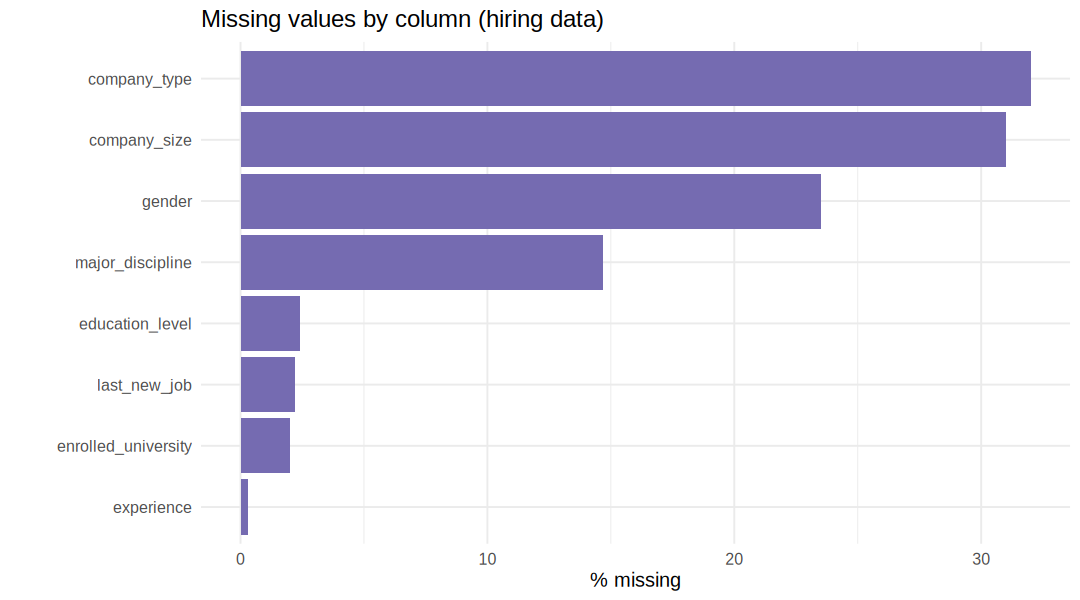

In [ ]:
missing_tbl <- data.frame(column = names(cand_raw),
                          n_missing = colSums(is.na(cand_raw)),
                          pct_missing = round(100 * colMeans(is.na(cand_raw)), 1),
                          row.names = NULL) %>%
  arrange(desc(n_missing))
print(missing_tbl)

print(
  ggplot(filter(missing_tbl, n_missing > 0), aes(x = reorder(column, pct_missing), y = pct_missing)) +
    geom_col(fill = "#756bb1") + coord_flip() +
    labs(title = "Missing values by column (hiring data)", x = NULL, y = "% missing")
)

cat("Duplicate enrollee IDs:", sum(duplicated(cand_raw$enrollee_id)), "\n")
cat("Rows sharing an identical profile with another row:",
    sum(duplicated(cand_raw %>% dplyr::select(-enrollee_id, -any_of("job_chnge"))) ), "\n")

cand_clean <- cand_raw %>%
  distinct(enrollee_id, .keep_all = TRUE) %>%
  mutate(

    experience_yrs = case_when(experience == "<1" ~ 0,
                               experience == ">20" ~ 21,
                               TRUE ~ suppressWarnings(as.numeric(experience))),

    last_new_job_yrs = case_when(last_new_job == "never" ~ 0,
                                 last_new_job == ">4" ~ 5,
                                 TRUE ~ suppressWarnings(as.numeric(last_new_job))),
    relevant_exp = ifelse(grepl("^Has", relevent_experience), "Relevant_Exp", "No_Relevant_Exp")
  ) %>%
  mutate(

    experience_yrs = ifelse(is.na(experience_yrs), median(experience_yrs, na.rm = TRUE), experience_yrs),
    last_new_job_yrs = ifelse(is.na(last_new_job_yrs), median(last_new_job_yrs, na.rm = TRUE), last_new_job_yrs),
    city_development_index = ifelse(is.na(city_development_index),
                                   median(city_development_index, na.rm = TRUE),
                                   city_development_index),

    across(c(gender, enrolled_university, education_level, major_discipline,
             company_size, company_type), ~ replace_na(.x, "Unknown")),

    Likely_Join = factor(ifelse(target == 0, "Yes", "No"), levels = c("No", "Yes"))
  ) %>%
  mutate(
    education_level = factor(education_level,
      levels = union(intersect(c("Unknown", "Primary School", "High School", "Graduate", "Masters", "Phd"),
                               unique(education_level)), unique(education_level))),
    company_size = factor(company_size,
      levels = union(intersect(c("Unknown", "<10", "10/49", "10-49", "50-99", "100-500", "500-999",
                                 "1000-4999", "5000-9999", "10000+"), unique(company_size)),
                     unique(company_size))),
    exp_band = make_exp_band(experience_yrs)
  )

model_cols <- c("city_development_index", "gender", "relevant_exp", "enrolled_university",
                "education_level", "major_discipline", "experience_yrs", "company_size",
                "company_type", "last_new_job_yrs", "training_hours")
cand_model <- cand_clean %>%
  dplyr::select(all_of(model_cols), Likely_Join) %>%
  mutate(across(where(is.character), as.factor))

glimpse(cand_model)
cat("\nClass balance (Likely_Join):\n")
print(round(prop.table(table(cand_model$Likely_Join)), 3))

# 3. Analysis and visualisation (hiring data)

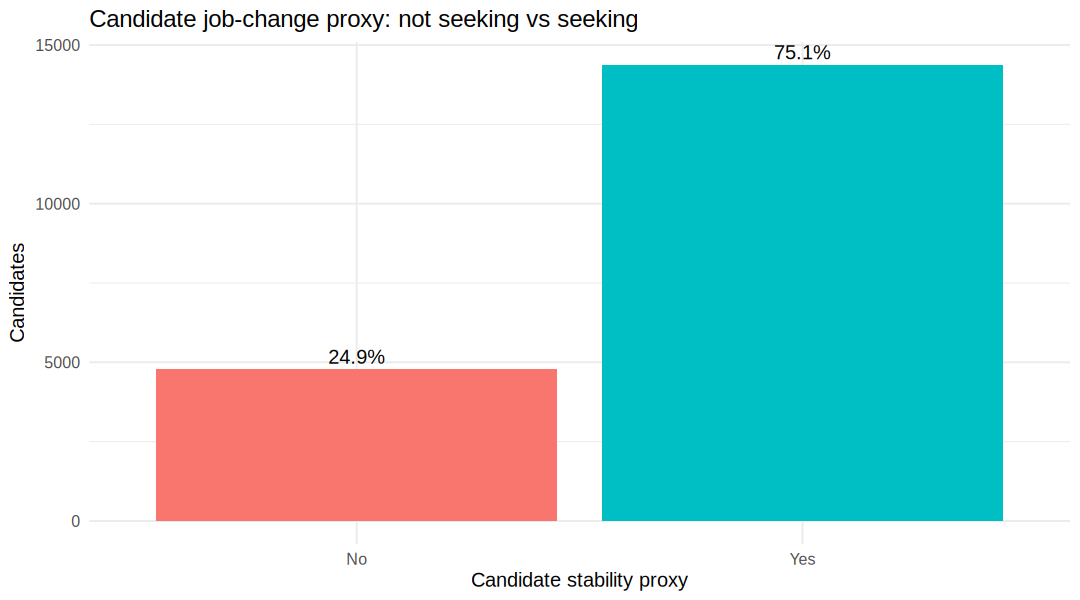

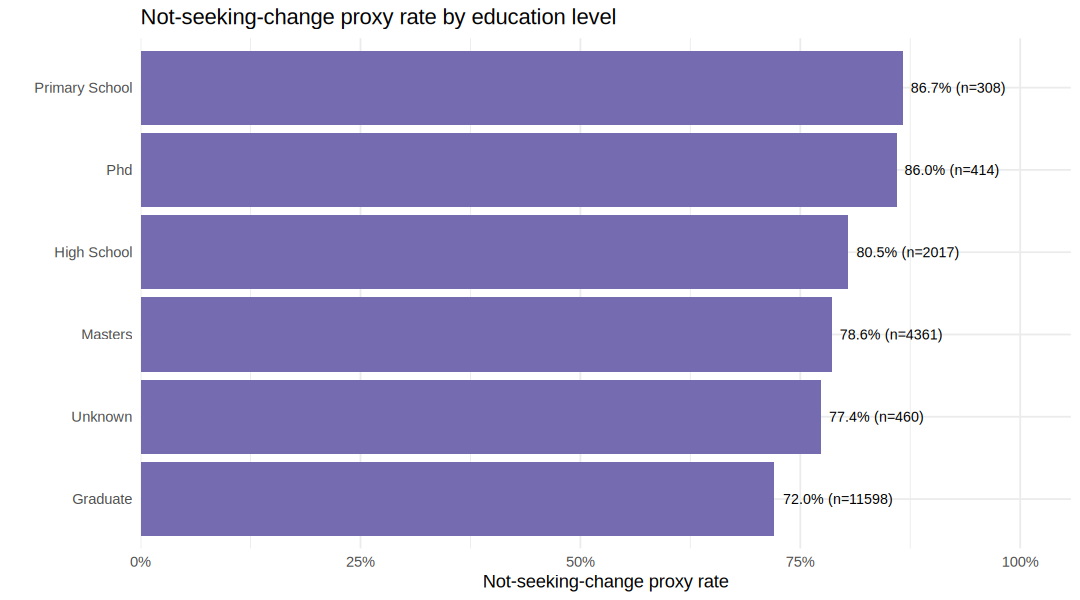

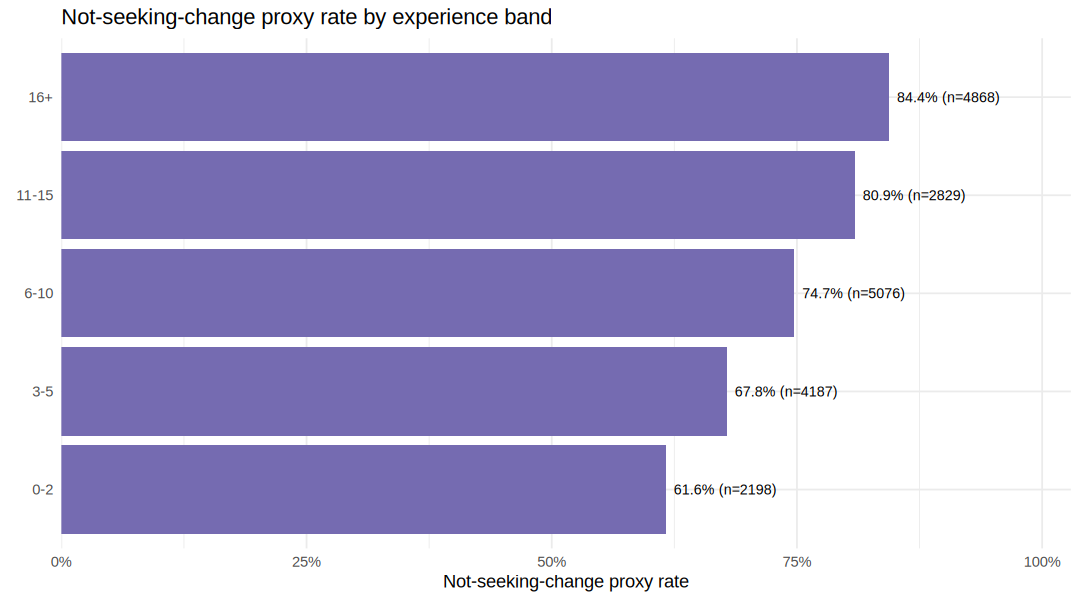

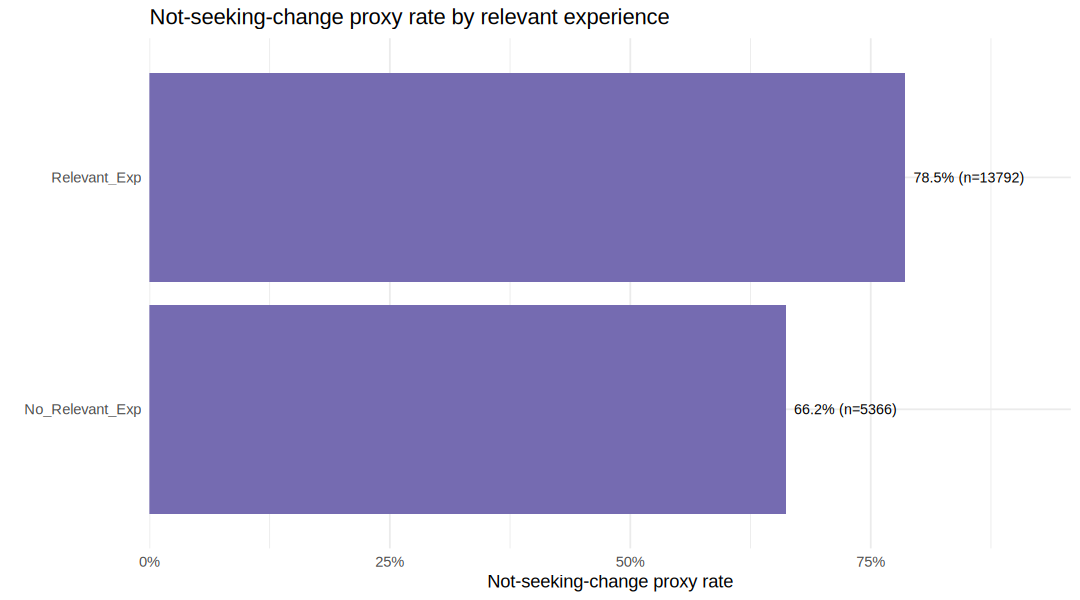

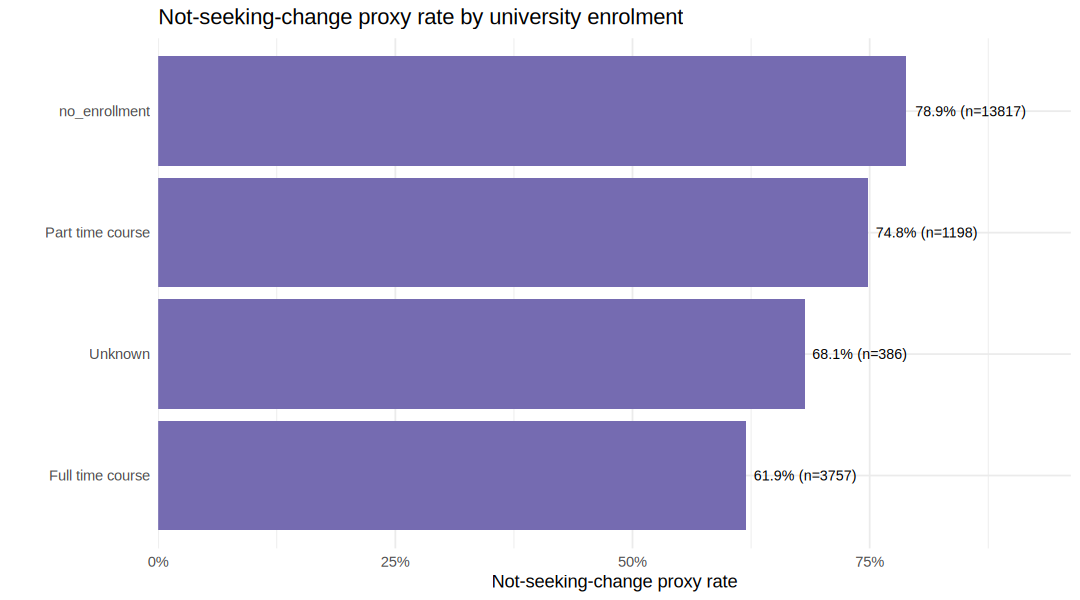

In [ ]:
print(
  cand_clean %>% count(Likely_Join) %>% mutate(pct = n / sum(n)) %>%
    ggplot(aes(x = Likely_Join, y = n, fill = Likely_Join)) +
    geom_col(show.legend = FALSE) +
    geom_text(aes(label = percent(pct, accuracy = 0.1)), vjust = -0.4) +
    labs(title = "Candidate job-change proxy: not seeking vs seeking", x = "Candidate stability proxy", y = "Candidates")
)

print(rate_bar(cand_clean, "education_level", "Likely_Join", "Yes",
               "Not-seeking-change proxy rate by education level", "Not-seeking-change proxy rate"))
print(rate_bar(cand_clean, "exp_band", "Likely_Join", "Yes",
               "Not-seeking-change proxy rate by experience band", "Not-seeking-change proxy rate"))
print(rate_bar(cand_clean, "relevant_exp", "Likely_Join", "Yes",
               "Not-seeking-change proxy rate by relevant experience", "Not-seeking-change proxy rate"))
print(rate_bar(cand_clean, "enrolled_university", "Likely_Join", "Yes",
               "Not-seeking-change proxy rate by university enrolment", "Not-seeking-change proxy rate"))

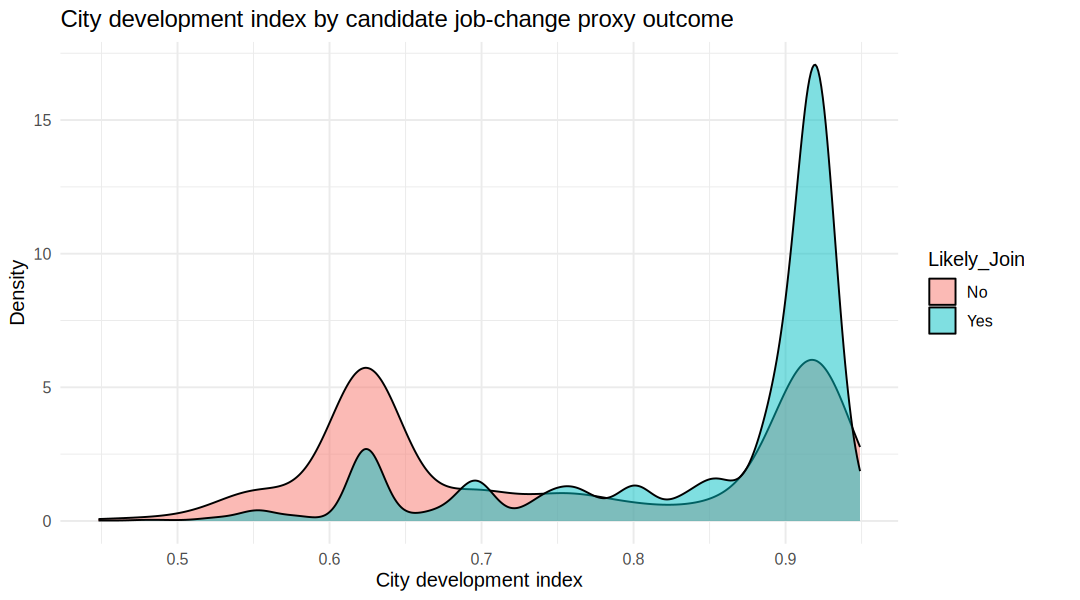

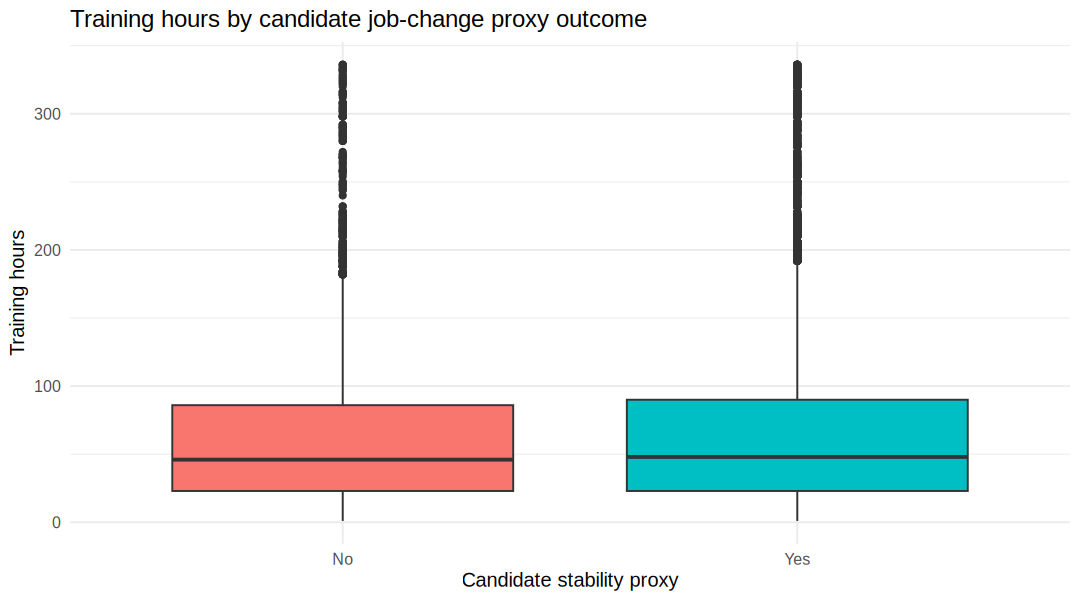

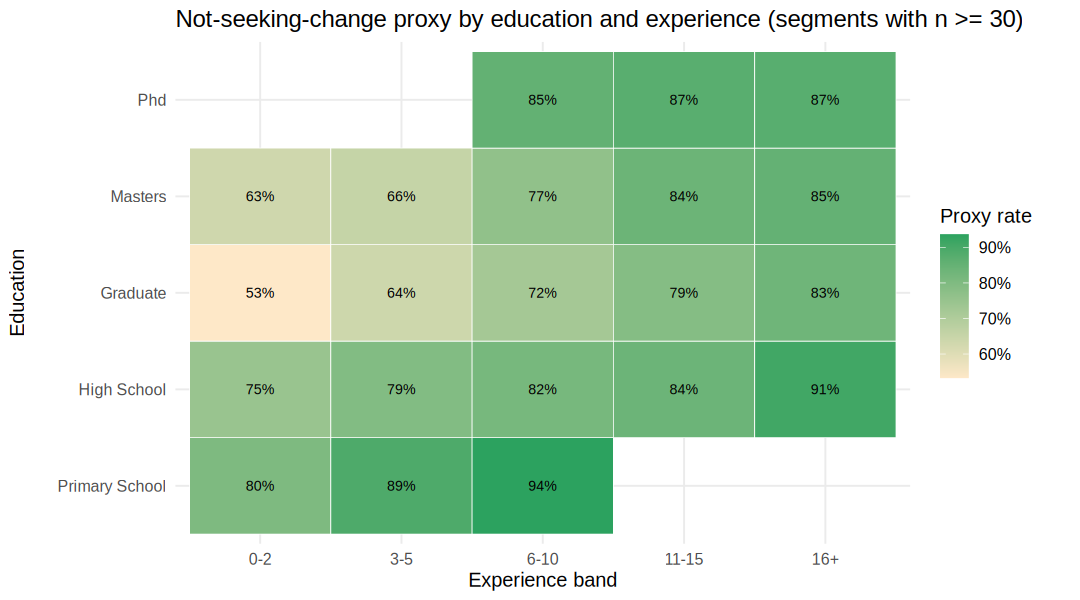

In [ ]:
print(
  ggplot(cand_clean, aes(x = city_development_index, fill = Likely_Join)) +
    geom_density(alpha = 0.5) +
    labs(title = "City development index by candidate job-change proxy outcome", x = "City development index", y = "Density")
)
print(
  ggplot(cand_clean, aes(x = Likely_Join, y = training_hours, fill = Likely_Join)) +
    geom_boxplot(show.legend = FALSE) +
    labs(title = "Training hours by candidate job-change proxy outcome", x = "Candidate stability proxy", y = "Training hours")
)

print(
  cand_clean %>%
    filter(education_level != "Unknown") %>%
    group_by(education_level, exp_band) %>%
    summarise(rate = mean(Likely_Join == "Yes"), n = n(), .groups = "drop") %>%
    filter(n >= 30) %>%
    ggplot(aes(x = exp_band, y = education_level, fill = rate)) +
    geom_tile(colour = "white") +
    geom_text(aes(label = percent(rate, accuracy = 1)), size = 3) +
    scale_fill_gradient(low = "#fee8c8", high = "#2ca25f", labels = percent) +
    labs(title = "Not-seeking-change proxy by education and experience (segments with n >= 30)",
         x = "Experience band", y = "Education", fill = "Proxy rate")
)

# 4. Logistic regression model (hiring data)

Logistic regression is suitable because the outcome is binary. Here, the positive class is the proxy for a candidate who is not currently seeking a job change; it is not observed offer acceptance. Coefficients can be summarised as odds ratios, which describe associations rather than causes.

Train: 14369 | Test: 4789 

Call:
glm(formula = Likely_Join ~ ., family = binomial, data = train_c)

Coefficients:
                                      Estimate Std. Error z value Pr(>|z|)    
(Intercept)                         -4.2446469  0.7088809  -5.988 2.13e-09 ***
city_development_index               5.8239030  0.1790745  32.522  < 2e-16 ***
genderMale                           0.2640685  0.0876432   3.013 0.002587 ** 
genderOther                          0.1380567  0.2371522   0.582 0.560470    
genderUnknown                        0.1557967  0.0936870   1.663 0.096323 .  
relevant_expRelevant_Exp             0.0889930  0.0574036   1.550 0.121069    
enrolled_universityno_enrollment     0.2067964  0.0583824   3.542 0.000397 ***
enrolled_universityPart time course  0.1637129  0.0969724   1.688 0.091365 .  
enrolled_universityUnknown           0.1831243  0.1476200   1.241 0.214786    
education_levelPrimary School        0.4490594  0.2504385   1.793 0.072958 .  
education_levelH

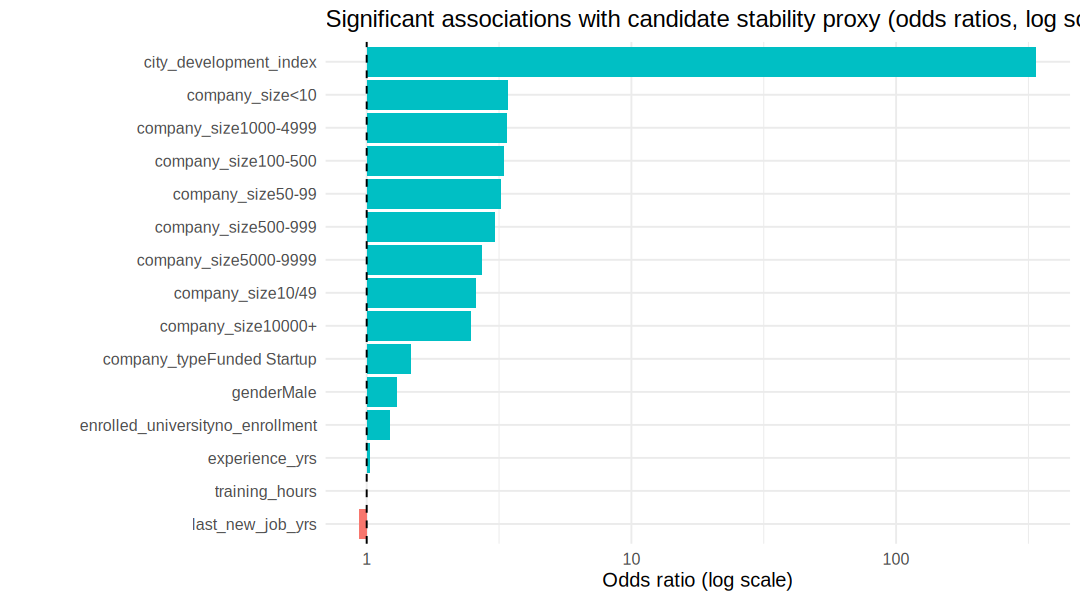

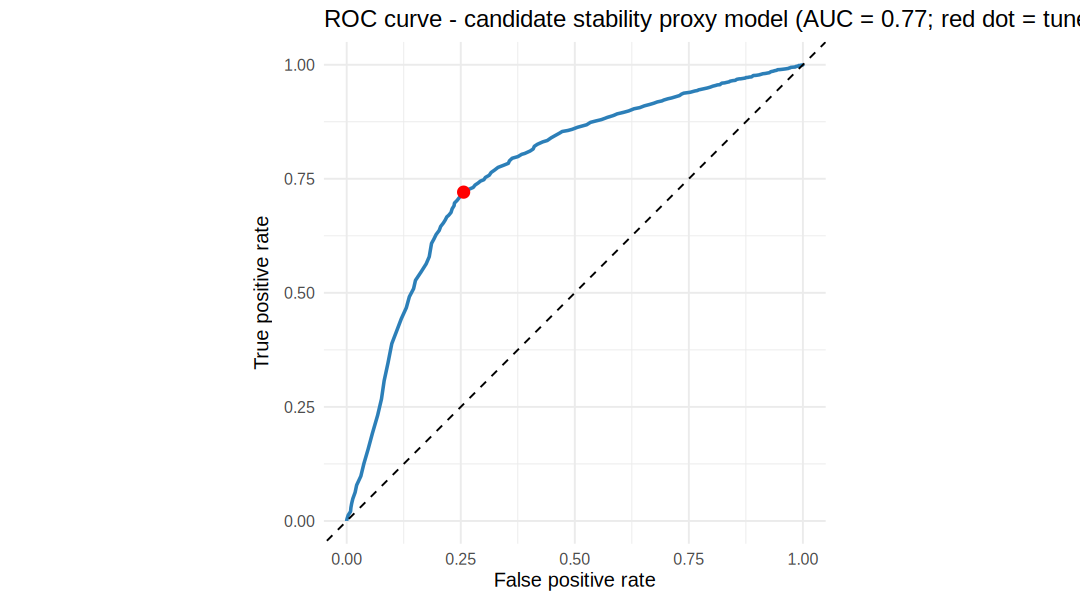

In [ ]:
train_idx_c <- as.vector(createDataPartition(cand_model$Likely_Join, p = 0.75, list = FALSE))
train_c <- cand_model[train_idx_c, ]
test_c  <- cand_model[-train_idx_c, ]
cat("Train:", nrow(train_c), "| Test:", nrow(test_c), "\n")

log_c <- glm(Likely_Join ~ ., data = train_c, family = binomial)
print(summary(log_c))

coef_c <- summary(log_c)$coefficients
or_tbl_c <- data.frame(term = rownames(coef_c), odds_ratio = exp(coef_c[, 1]),
                       p_value = coef_c[, 4], row.names = NULL) %>%
  filter(term != "(Intercept)", p_value < 0.05) %>%
  arrange(desc(odds_ratio))
print(or_tbl_c)

print(
  ggplot(or_tbl_c, aes(x = reorder(term, odds_ratio), y = odds_ratio, fill = odds_ratio > 1)) +
    geom_col(show.legend = FALSE) + geom_hline(yintercept = 1, linetype = "dashed") +
    coord_flip() + scale_y_log10() +
    labs(title = "Significant associations with candidate stability proxy (odds ratios, log scale)",
         x = NULL, y = "Odds ratio (log scale)")
)

prob_train_c <- predict(log_c, newdata = train_c, type = "response")
thr_c <- youden_threshold(prob_train_c, train_c$Likely_Join)
test_c$prob <- predict(log_c, newdata = test_c, type = "response")

res_c_default <- eval_model(test_c$prob, test_c$Likely_Join, 0.5, "Candidate proxy - threshold 0.5")
res_c_tuned   <- eval_model(test_c$prob, test_c$Likely_Join, thr_c, "Candidate proxy - tuned threshold")
print(res_c_tuned$cm)
print(rbind(res_c_default$row, res_c_tuned$row))

roc_c <- roc_points(test_c$prob, test_c$Likely_Join)
op_c  <- roc_c[which.min(abs(roc_c$threshold - thr_c)), ]
print(
  ggplot(roc_c, aes(x = FPR, y = TPR)) + geom_line(colour = "#2c7fb8", linewidth = 1) +
    geom_abline(linetype = "dashed") +
    geom_point(data = op_c, colour = "red", size = 3) + coord_equal() +
    labs(title = paste0("ROC curve - candidate stability proxy model (AUC = ", round(res_c_tuned$row$AUC, 3),
                        "; red dot = tuned threshold ", thr_c, ")"),
         x = "False positive rate", y = "True positive rate")
)

# 5. LIME - why is a specific candidate ranked high or low? (hiring data)

**Advanced extension:** LIME explains individual predictions locally. For a short review, explain what the plot means rather than describing every implementation detail.



LIME plot saved as hiring_lime_explanations.png


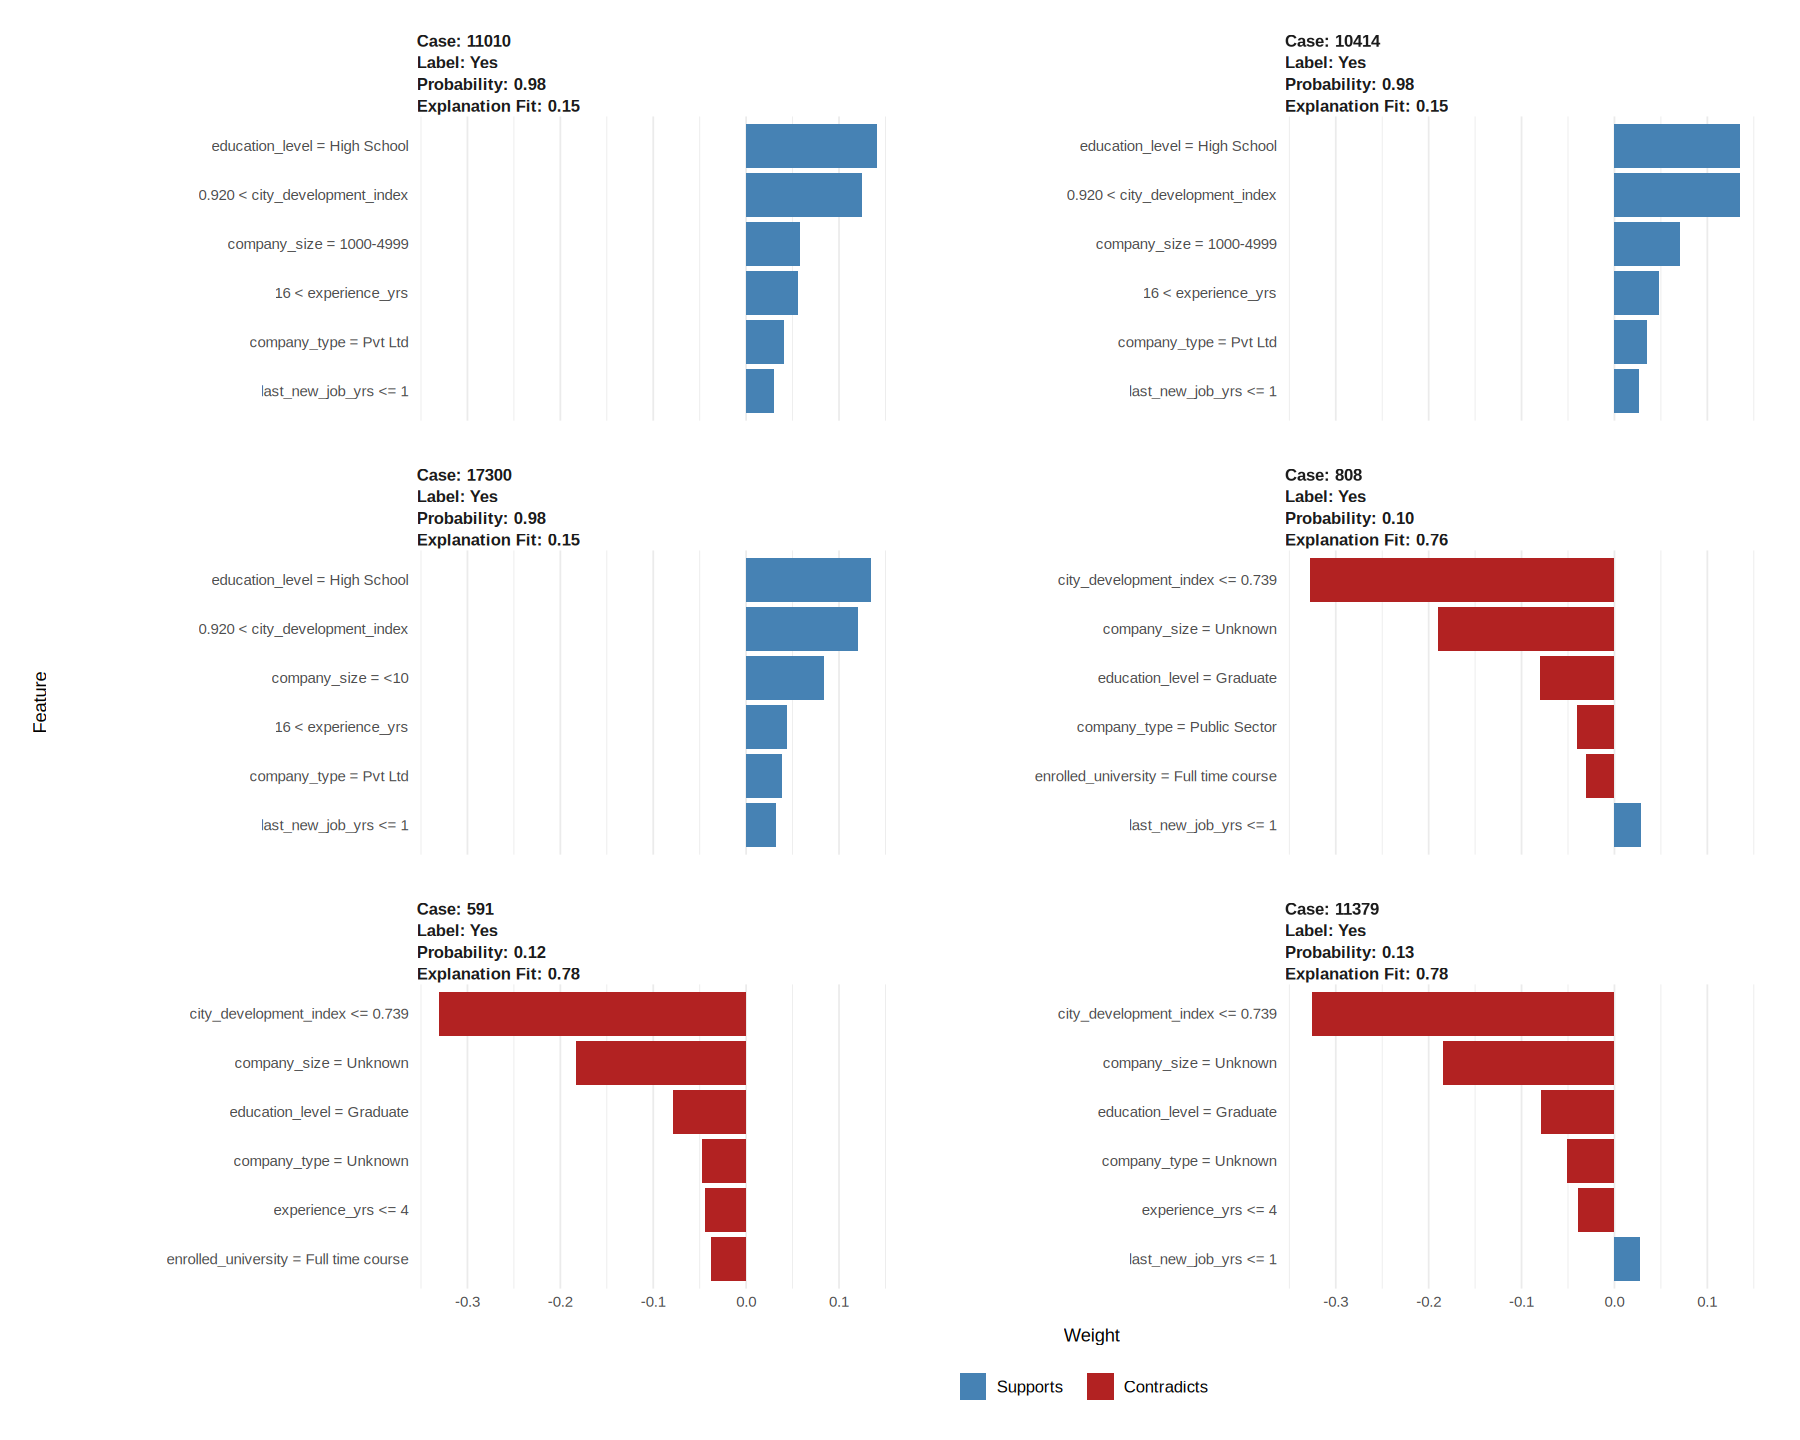

In [ ]:

# ============================================================
# LIME EXPLANATIONS - IMPROVED SPACING AND VISIBILITY
# ============================================================

# Train the model with 5-fold cross-validation
caret_c <- caret::train(
  Likely_Join ~ .,
  data = train_c,
  method = "glm",
  family = "binomial",
  trControl = caret::trainControl(
    method = "cv",
    number = 5,
    classProbs = TRUE
  )
)

# Prepare the explainer
pred_cols_c <- setdiff(names(train_c), "Likely_Join")

explainer_c <- lime::lime(
  as.data.frame(train_c[, pred_cols_c, drop = FALSE]),
  caret_c
)

# Select the 3 highest and 3 lowest predicted probabilities
idx_c <- unique(c(
  order(test_c$prob, decreasing = TRUE)[1:3],
  order(test_c$prob)[1:3]
))

lime_cases_c <- as.data.frame(
  test_c[idx_c, pred_cols_c, drop = FALSE]
)

# Generate LIME explanations
explanation_c <- lime::explain(
  lime_cases_c,
  explainer_c,
  labels = "Yes",
  n_features = 6
)

# Increase the notebook plot output size
options(
  repr.plot.width = 15,
  repr.plot.height = 12
)

# Create a more readable plot
lime_plot_c <- lime::plot_features(
  explanation_c,
  ncol = 2
) +
  ggplot2::theme(
    strip.text = ggplot2::element_text(
      size = 10,
      face = "bold",
      margin = ggplot2::margin(5, 5, 5, 5)
    ),
    axis.text.x = ggplot2::element_text(size = 9),
    axis.text.y = ggplot2::element_text(size = 9),
    axis.title = ggplot2::element_text(size = 11),
    legend.text = ggplot2::element_text(size = 10),
    legend.position = "bottom",
    panel.spacing.x = grid::unit(1.5, "lines"),
    panel.spacing.y = grid::unit(1.8, "lines"),
    plot.margin = ggplot2::margin(18, 20, 18, 20)
  )

# Display the improved plot
print(lime_plot_c)

# Save a high-resolution copy for your case study presentation
ggplot2::ggsave(
  filename = "hiring_lime_explanations.png",
  plot = lime_plot_c,
  width = 15,
  height = 12,
  units = "in",
  dpi = 300,
  bg = "white"
)

cat("\nLIME plot saved as hiring_lime_explanations.png\n")


# 6. Association rules - which profile combinations are associated with the candidate stability proxy?

**Advanced extension:** Association rules find combinations that occur with the proxy outcome. They do not establish that a condition causes a candidate to join or leave.


=== Profiles associated with not seeking a job change (proxy -> Likely_Join=Yes) ===
                                                                                            rule
              {Major=Unknown,LastJobGap=Never_Changed,CityDev=HighDev_City} => {Likely_Join=Yes}
                          {Major=STEM,CompanySize=<10,CityDev=HighDev_City} => {Likely_Join=Yes}
              {Relevance=Relevant_Exp,CompanySize=<10,CityDev=HighDev_City} => {Likely_Join=Yes}
   {Relevance=Relevant_Exp,CompanyType=Funded Startup,CityDev=HighDev_City} => {Likely_Join=Yes}
 {University=no_enrollment,CompanyType=Funded Startup,CityDev=HighDev_City} => {Likely_Join=Yes}
                          {CompanyType=Funded Startup,CityDev=HighDev_City} => {Likely_Join=Yes}
          {University=no_enrollment,CompanySize=50-99,CityDev=HighDev_City} => {Likely_Join=Yes}
            {University=no_enrollment,CompanySize=<10,CityDev=HighDev_City} => {Likely_Join=Yes}
               {Education=Masters,Company

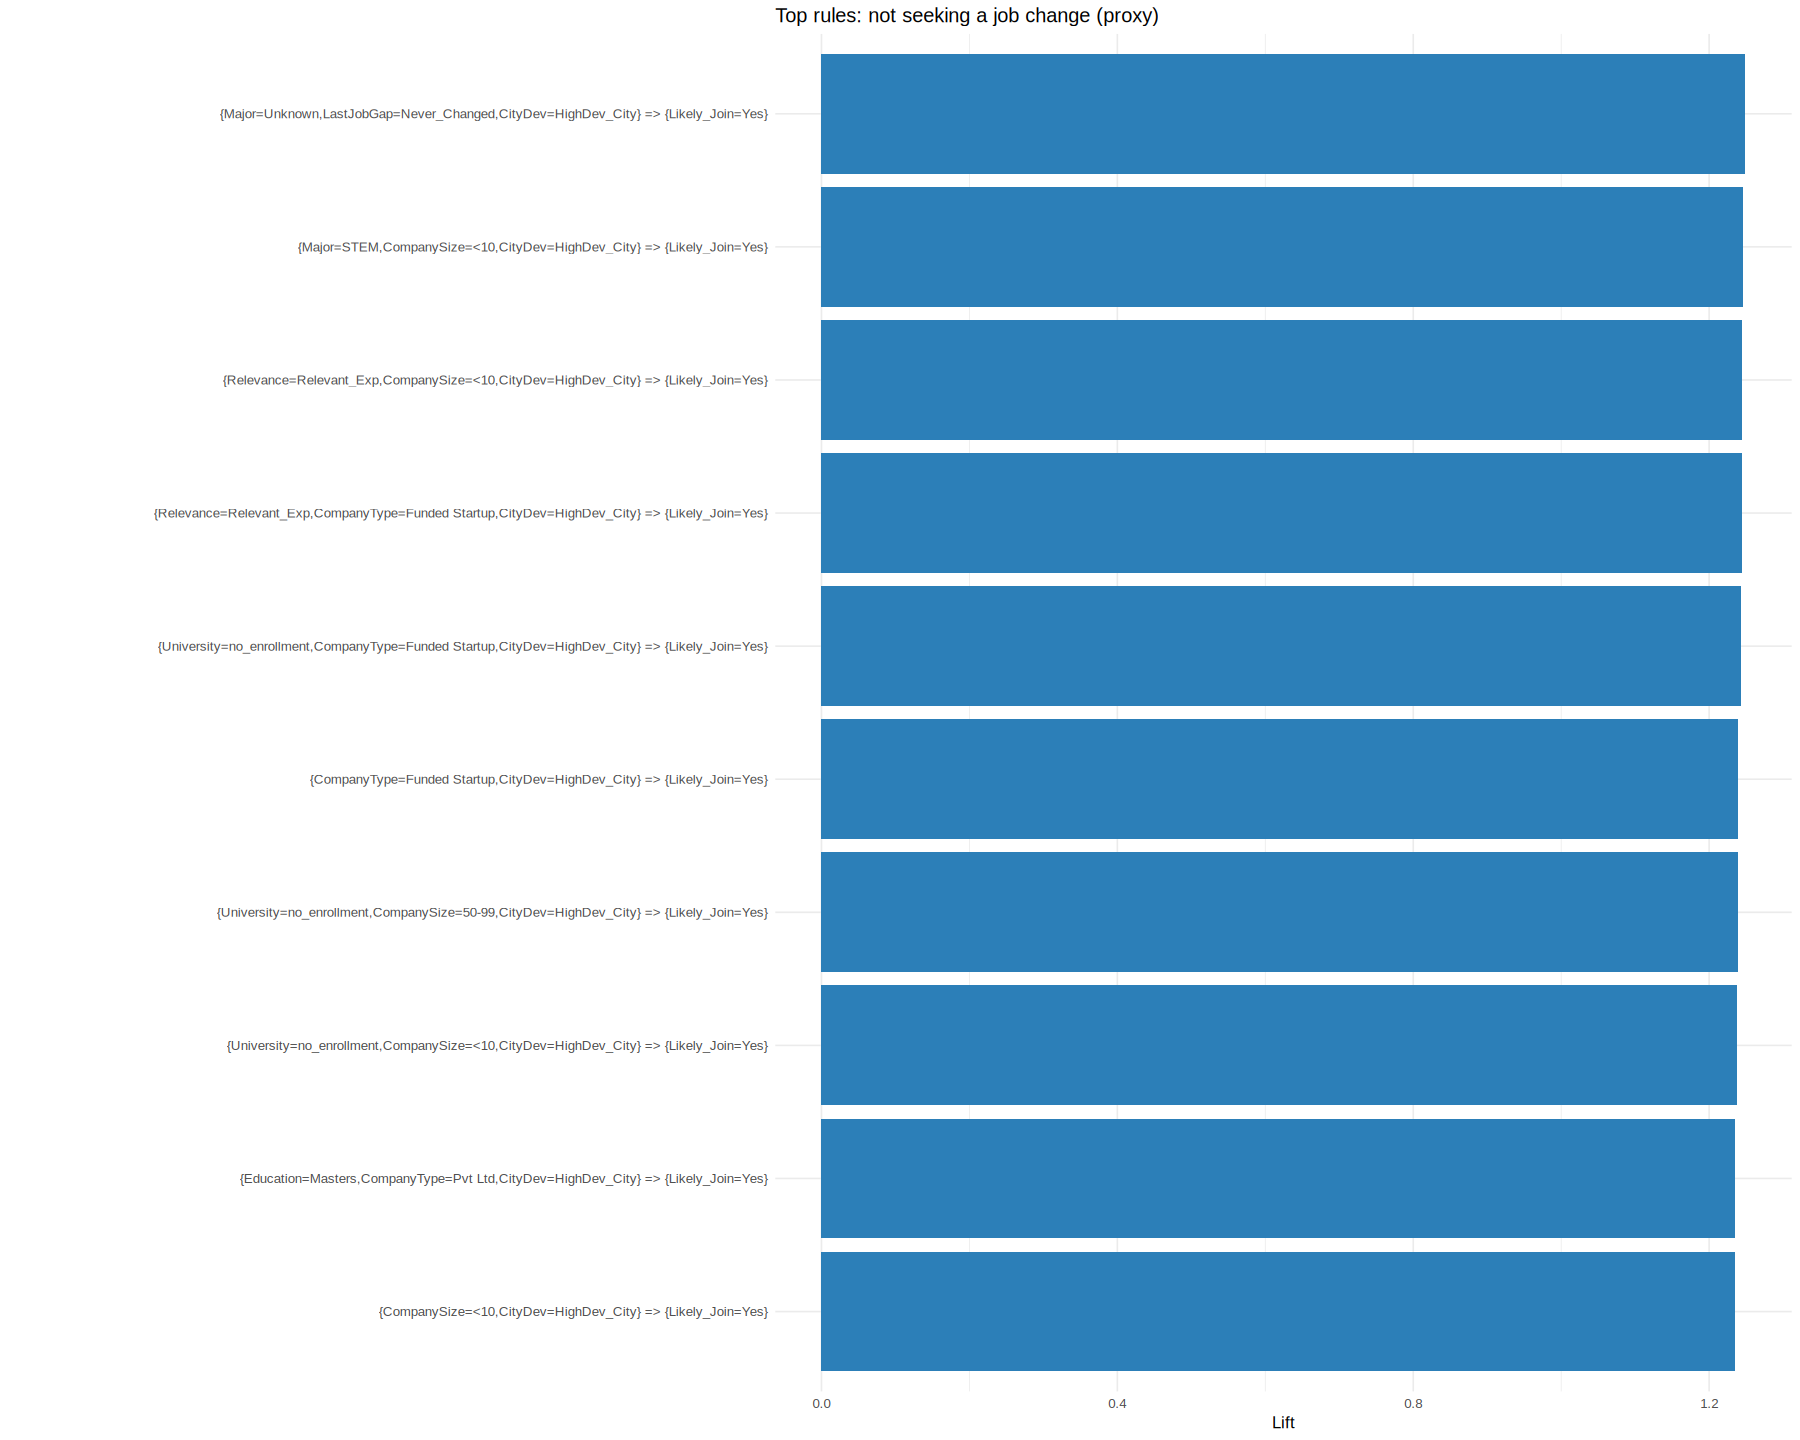


=== Not-seeking-change proxy - excluding rules that use 'Unknown' values ===
                                                                                            rule
                          {Major=STEM,CompanySize=<10,CityDev=HighDev_City} => {Likely_Join=Yes}
              {Relevance=Relevant_Exp,CompanySize=<10,CityDev=HighDev_City} => {Likely_Join=Yes}
   {Relevance=Relevant_Exp,CompanyType=Funded Startup,CityDev=HighDev_City} => {Likely_Join=Yes}
 {University=no_enrollment,CompanyType=Funded Startup,CityDev=HighDev_City} => {Likely_Join=Yes}
                          {CompanyType=Funded Startup,CityDev=HighDev_City} => {Likely_Join=Yes}
          {University=no_enrollment,CompanySize=50-99,CityDev=HighDev_City} => {Likely_Join=Yes}
            {University=no_enrollment,CompanySize=<10,CityDev=HighDev_City} => {Likely_Join=Yes}
               {Education=Masters,CompanyType=Pvt Ltd,CityDev=HighDev_City} => {Likely_Join=Yes}
                                     {CompanySize

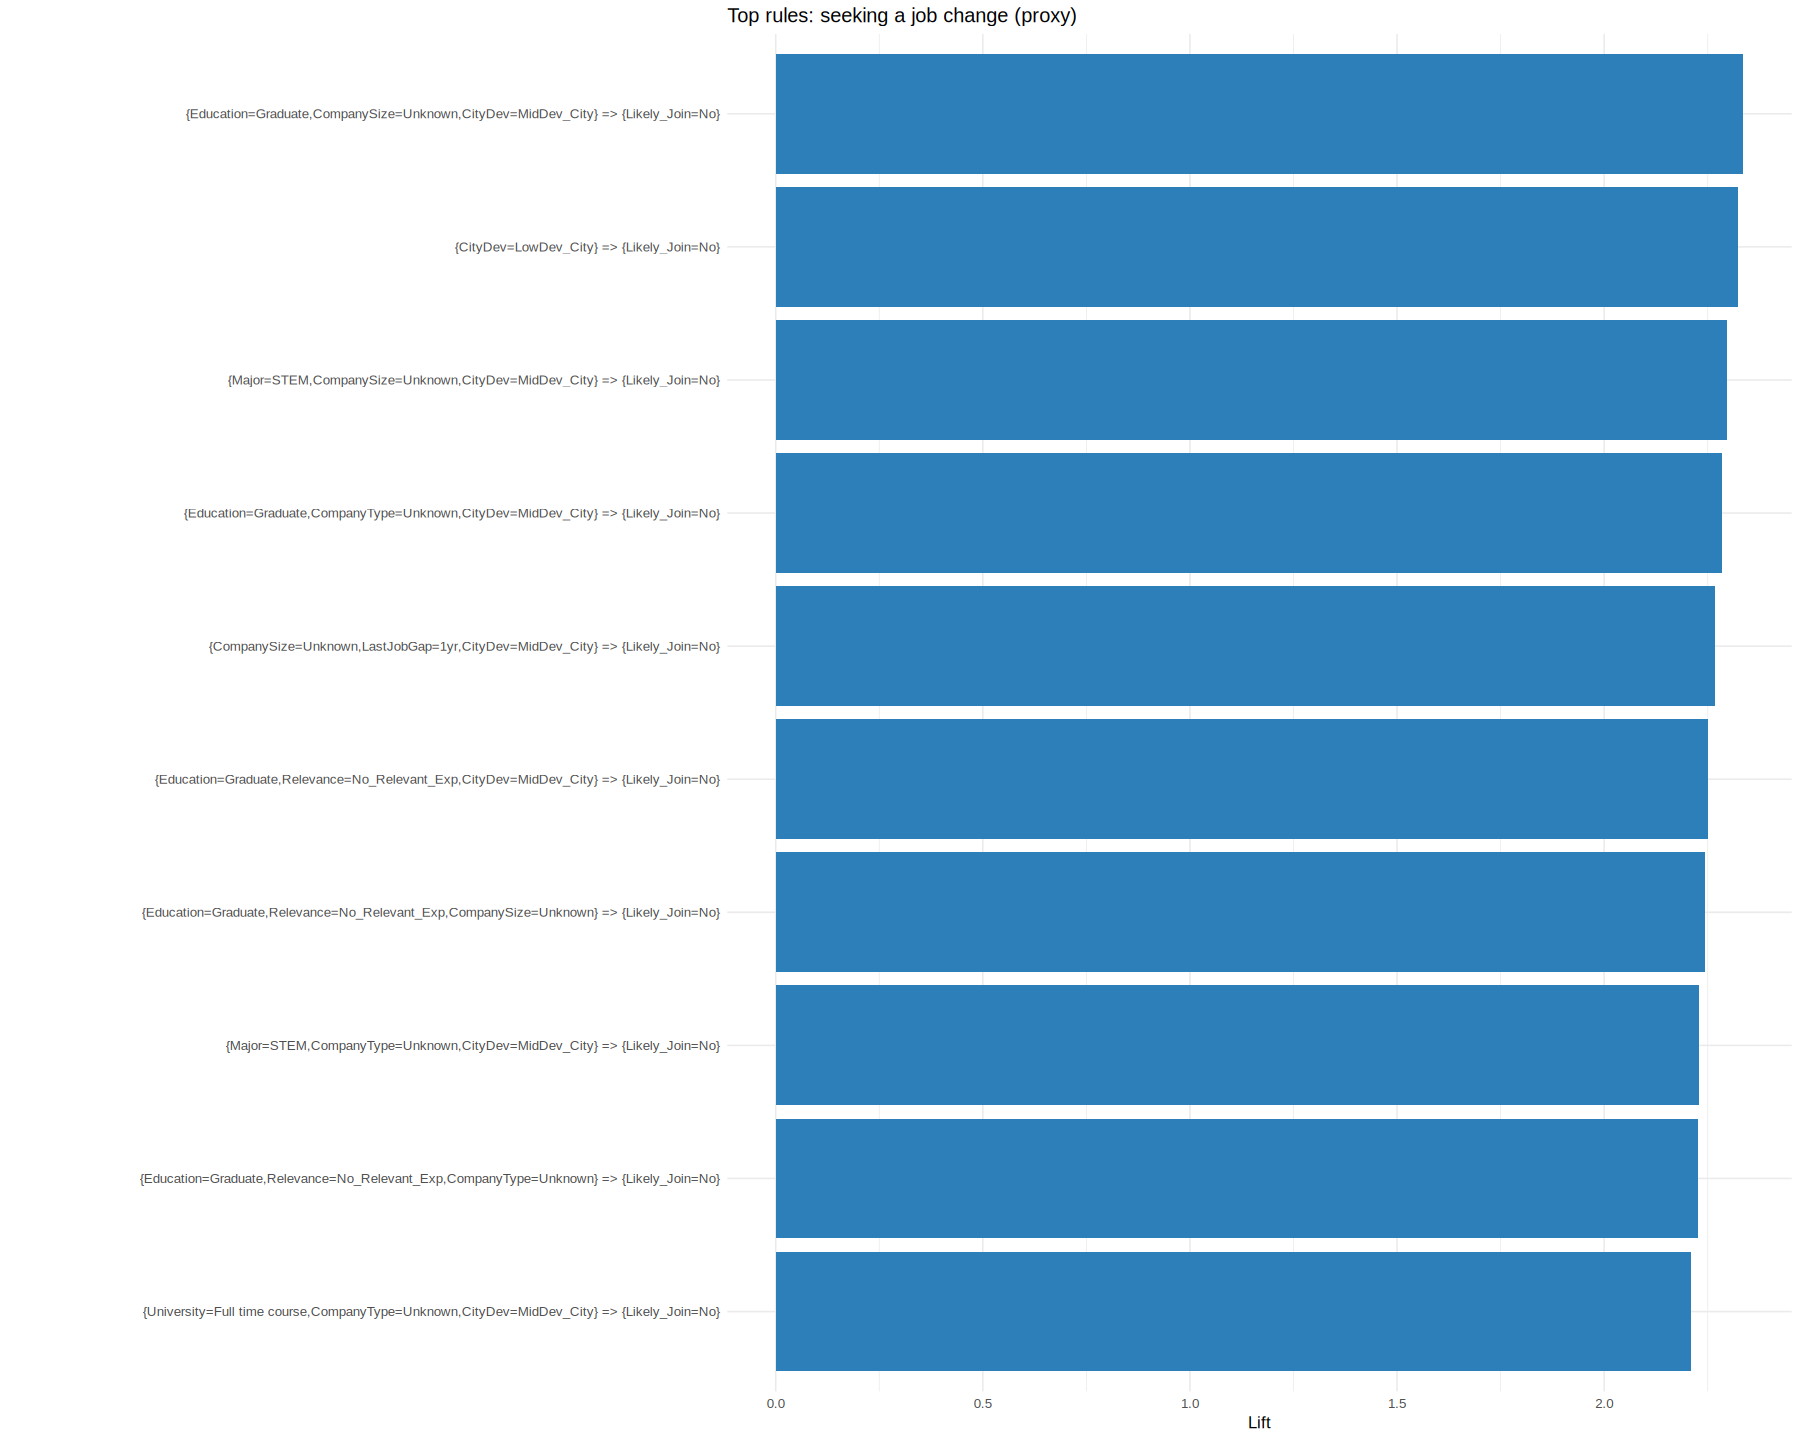


=== Seeking-change proxy - excluding rules that use 'Unknown' values ===
                                                                                            rule
                                                       {CityDev=LowDev_City} => {Likely_Join=No}
          {Education=Graduate,Relevance=No_Relevant_Exp,CityDev=MidDev_City} => {Likely_Join=No}
                  {Relevance=No_Relevant_Exp,Major=STEM,CityDev=MidDev_City} => {Likely_Join=No}
 {Relevance=No_Relevant_Exp,University=Full time course,CityDev=MidDev_City} => {Likely_Join=No}
                                           {ExpBand=0-2,CityDev=MidDev_City} => {Likely_Join=No}
                                {ExpBand=3-5,Major=STEM,CityDev=MidDev_City} => {Likely_Join=No}
        {Education=Graduate,University=Full time course,CityDev=MidDev_City} => {Likely_Join=No}
                {University=Full time course,Major=STEM,CityDev=MidDev_City} => {Likely_Join=No}
                        {ExpBand=3-5,Education=Gradua

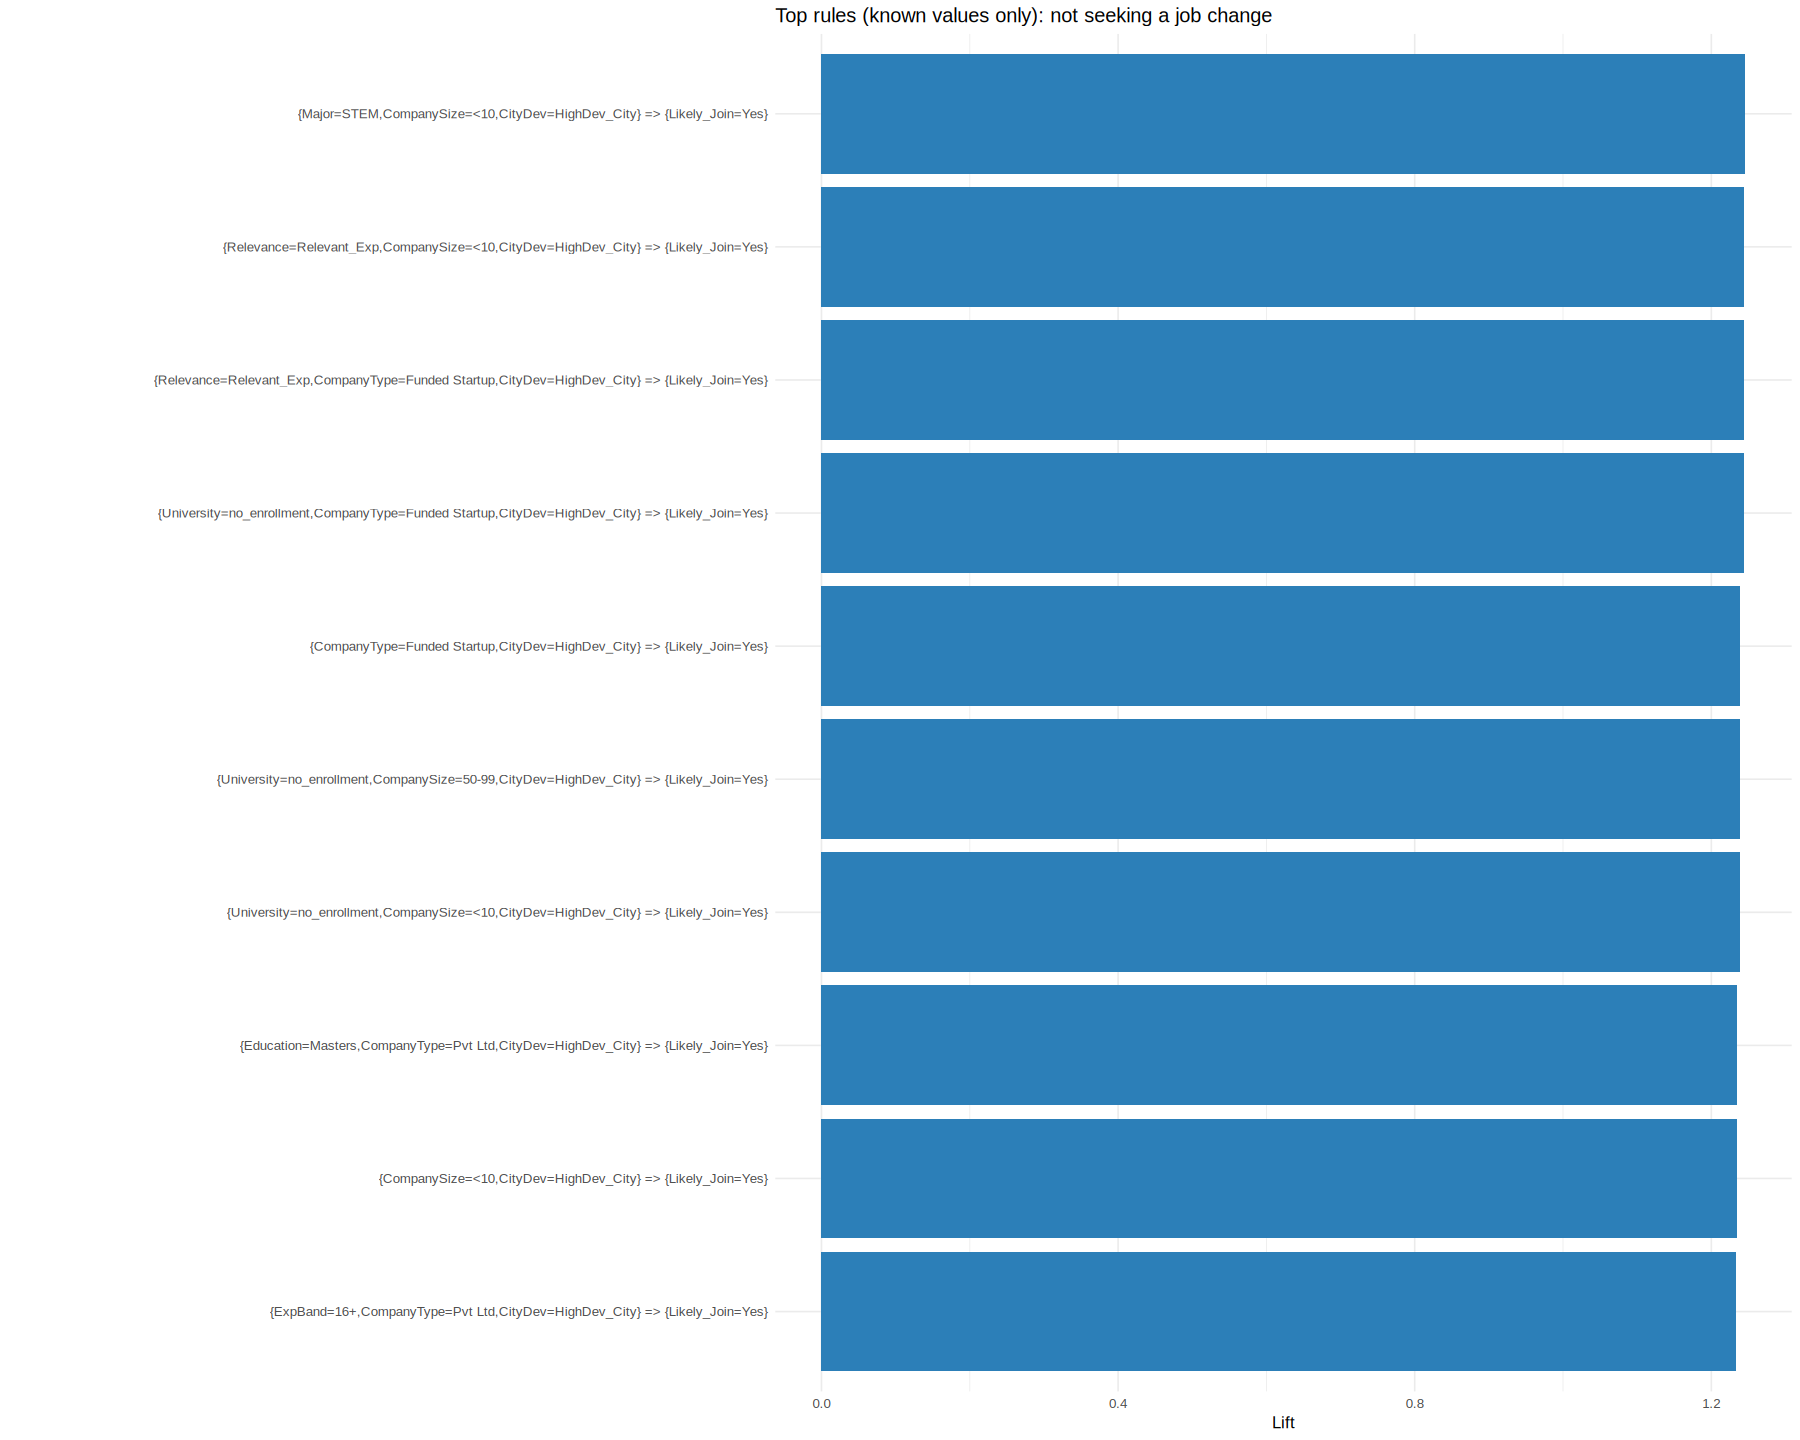

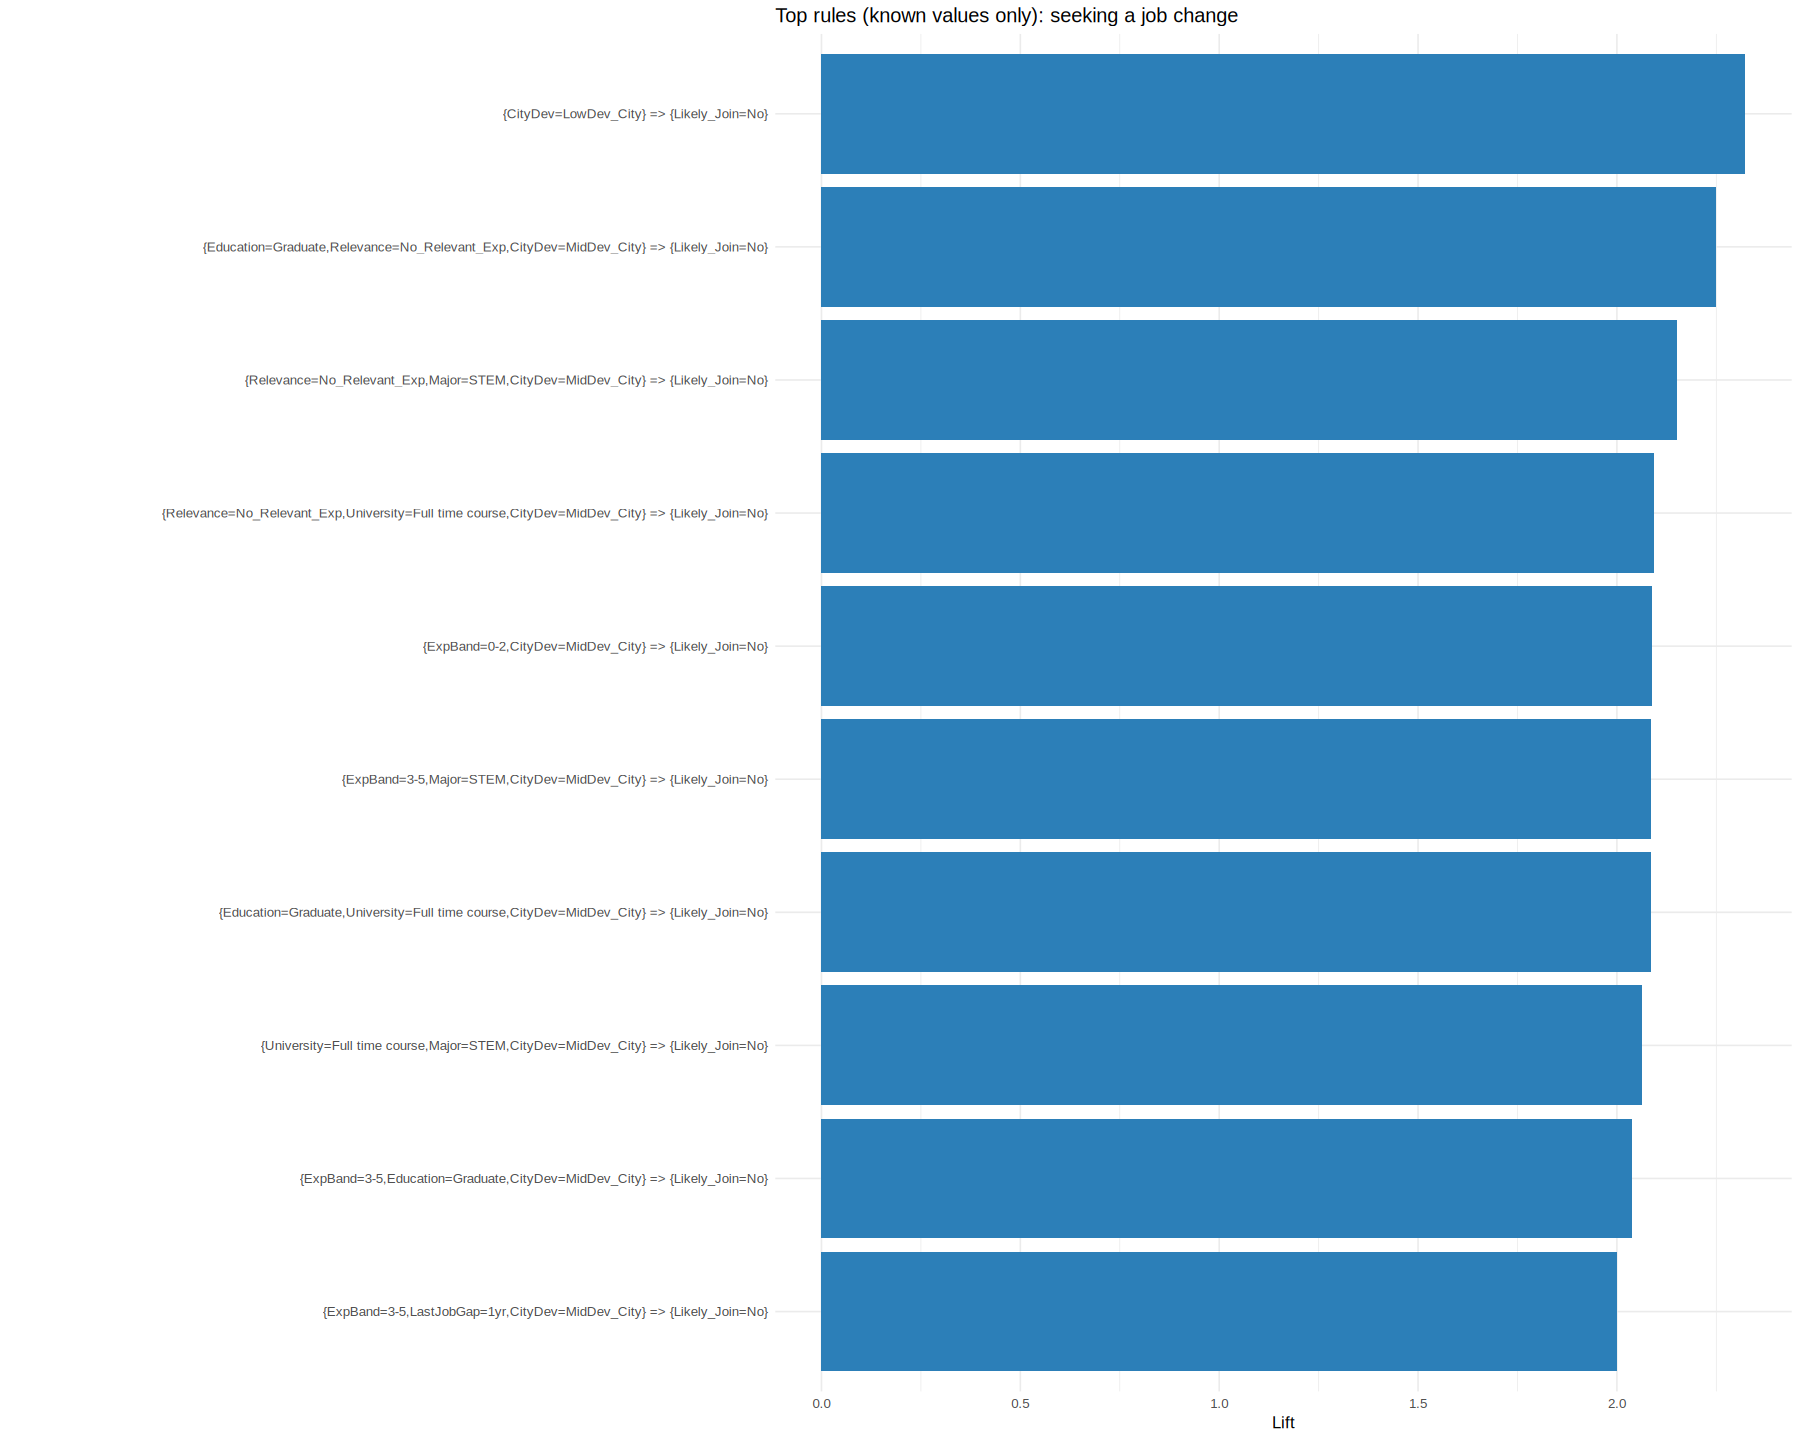

In [ ]:
cand_arules <- cand_clean %>%
  transmute(
    Likely_Join,
    ExpBand     = exp_band,
    Education   = education_level,
    Relevance   = factor(relevant_exp),
    University  = factor(enrolled_university),
    Major       = factor(major_discipline),
    CompanyType = factor(company_type),
    CompanySize = company_size,
    LastJobGap  = cut(last_new_job_yrs, breaks = c(-Inf, 0, 1, 4, Inf),
                      labels = c("Never_Changed", "1yr", "2-4yrs", "5plus_yrs")),
    CityDev     = cut(city_development_index, breaks = 3,
                      labels = c("LowDev_City", "MidDev_City", "HighDev_City")),
    Training    = factor(ntile(training_hours, 3),
                         labels = c("Short_Training", "Medium_Training", "Long_Training"))
  ) %>%
  mutate(across(everything(), as.factor))

trans_c <- as(cand_arules, "transactions")

rules_join   <- mine_rules(trans_c, "Likely_Join=Yes", supp = 0.03, conf = 0.90)
rules_notjoin <- mine_rules(trans_c, "Likely_Join=No",  supp = 0.02, conf = 0.45)

cat("\n=== Profiles associated with not seeking a job change (proxy -> Likely_Join=Yes) ===\n")
show_rules(rules_join, "Top rules: not seeking a job change (proxy)", "candidate_join_rules.csv")

cat("\n=== Profiles associated with seeking a job change (proxy -> Likely_Join=No) ===\n")
show_rules(rules_notjoin, "Top rules: seeking a job change (proxy)", "candidate_notjoin_rules.csv")

cat("\n=== Not-seeking-change proxy - excluding rules that use 'Unknown' values ===\n")
show_rules(drop_unknown(rules_join), "Top rules (known values only): not seeking a job change")

cat("\n=== Seeking-change proxy - excluding rules that use 'Unknown' values ===\n")
show_rules(drop_unknown(rules_notjoin), "Top rules (known values only): seeking a job change")

# 7. Candidate shortlist - ranking profiles by the stability proxy

The ranking is based on predicted proxy probability, not verified joining probability. Use it as a demonstration of ranking and model calibration, not as an automated hiring decision.

# A tibble: 5 × 4
   tier candidates avg_predicted actual_proxy_rate
  <int>      <int>         <dbl>             <dbl>
1     1        958         0.935             0.914
2     2        958         0.896             0.914
3     3        958         0.833             0.857
4     4        958         0.673             0.618
5     5        957         0.432             0.449
   enrollee_id education_level major_discipline experience_yrs    relevant_exp
1        29677     High School          Unknown             18    Relevant_Exp
2        21521     High School          Unknown             21    Relevant_Exp
3        14465     High School          Unknown             21    Relevant_Exp
4        25335  Primary School          Unknown             21    Relevant_Exp
5        28963     High School          Unknown             21    Relevant_Exp
6        10768     High School          Unknown             21    Relevant_Exp
7          114         Unknown          Unknown             21    Releva

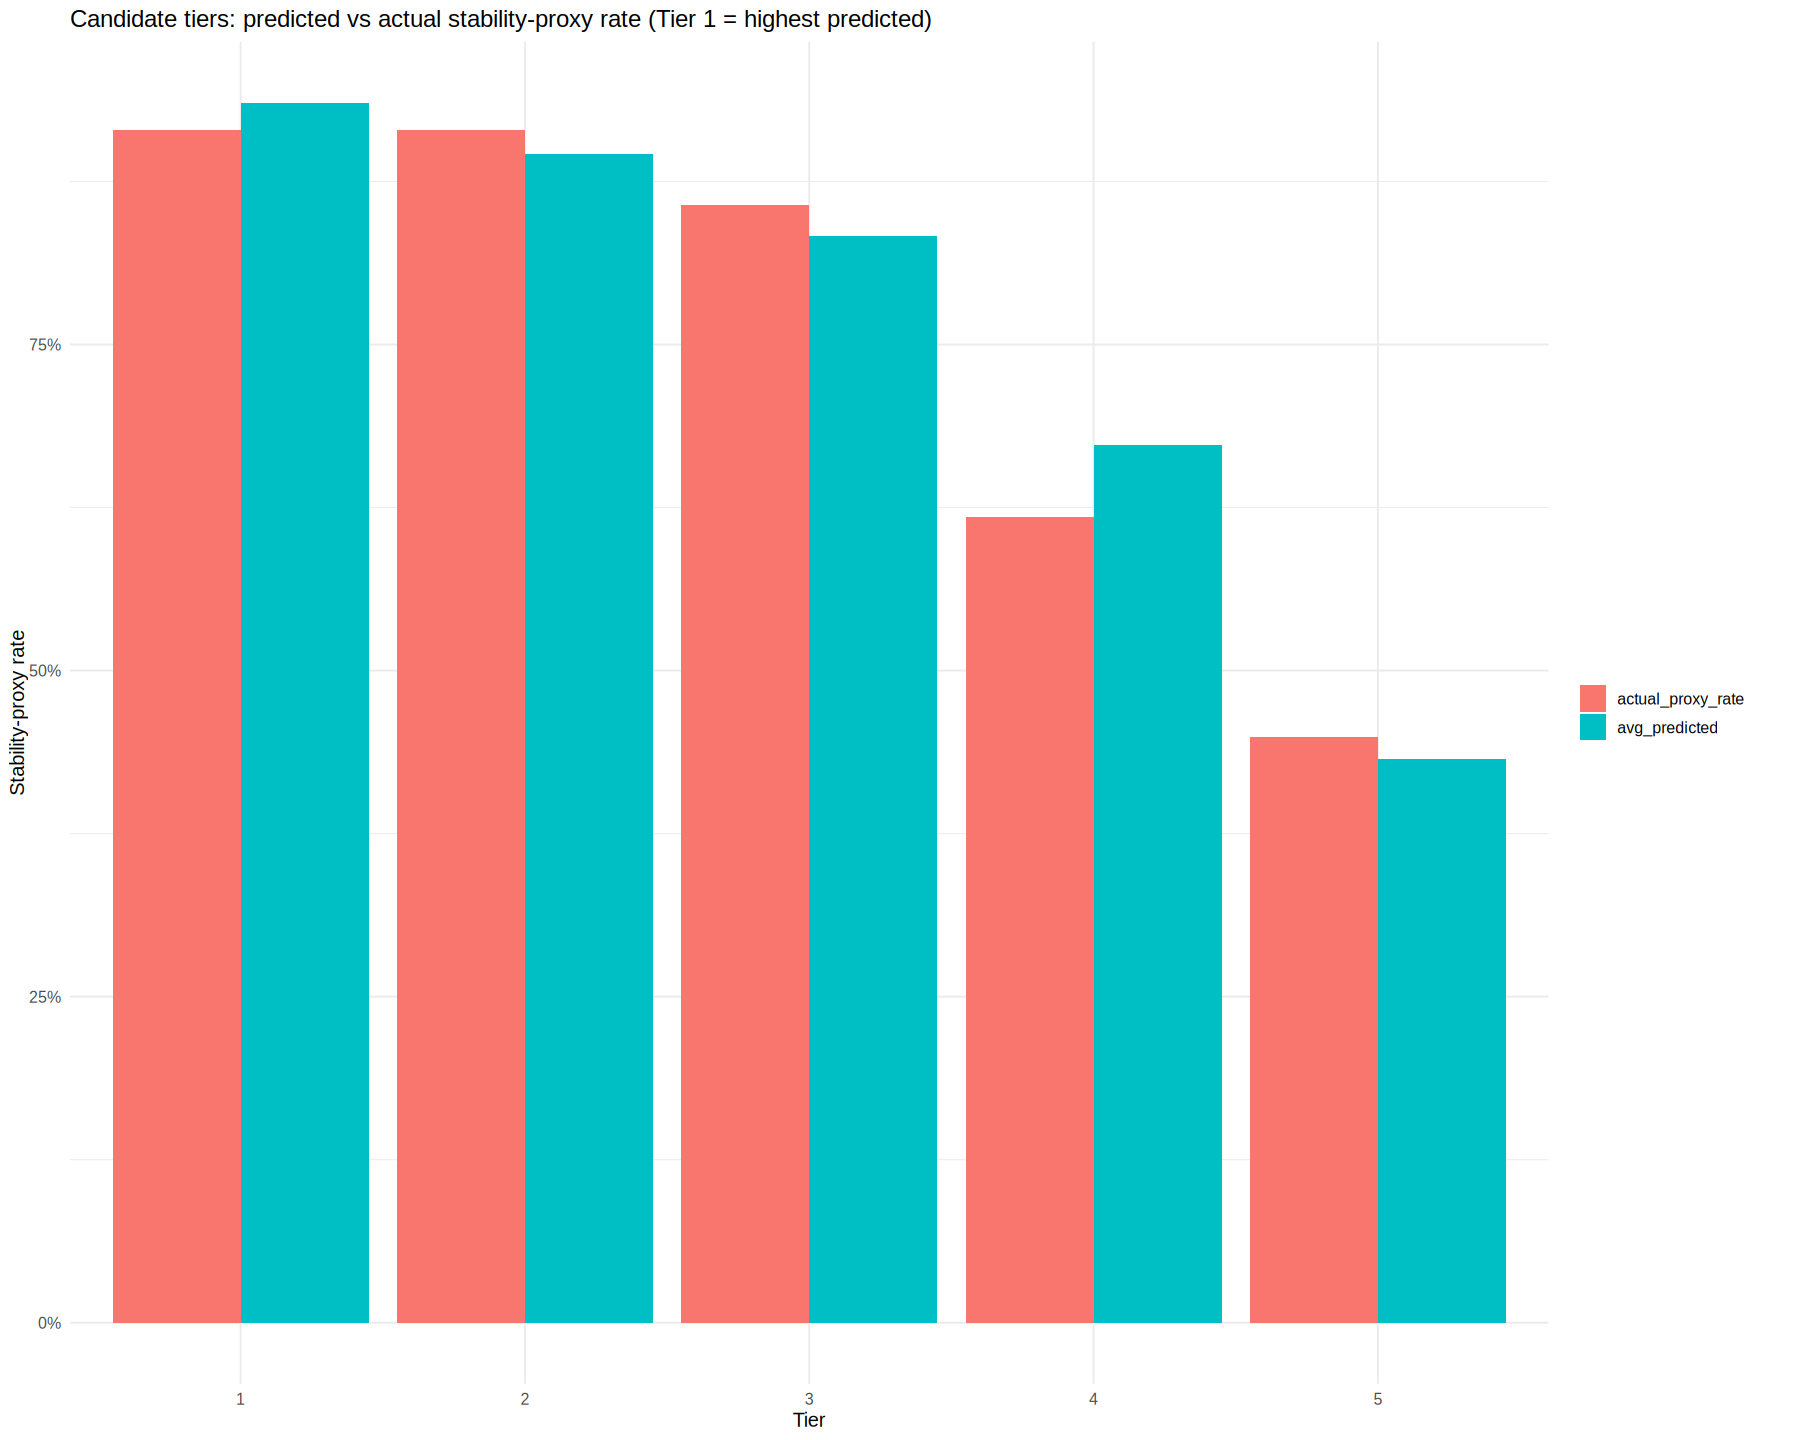

In [ ]:
shortlist <- cand_clean[-train_idx_c, ] %>%
  mutate(prob_join = test_c$prob) %>%
  dplyr::select(enrollee_id, education_level, major_discipline, experience_yrs, relevant_exp,
                company_type, last_new_job_yrs, training_hours, prob_join, Likely_Join) %>%
  mutate(tier = ntile(desc(prob_join), 5))

tier_summary <- shortlist %>%
  group_by(tier) %>%
  summarise(candidates = n(),
            avg_predicted = mean(prob_join),
            actual_proxy_rate = mean(Likely_Join == "Yes"), .groups = "drop")
print(tier_summary)

print(
  tier_summary %>%
    pivot_longer(c(avg_predicted, actual_proxy_rate), names_to = "measure", values_to = "rate") %>%
    ggplot(aes(x = factor(tier), y = rate, fill = measure)) +
    geom_col(position = "dodge") +
    scale_y_continuous(labels = percent) +
    labs(title = "Candidate tiers: predicted vs actual stability-proxy rate (Tier 1 = highest predicted)",
         x = "Tier", y = "Stability-proxy rate", fill = NULL)
)

top_candidates <- shortlist %>%
  arrange(desc(prob_join)) %>%
  slice_head(n = 15) %>%
  mutate(prob_join = round(prob_join, 3))
print(top_candidates)
write.csv(top_candidates, "top_candidates_shortlist.csv", row.names = FALSE)

# PART B - RETENTION MODULE: Who is likely to leave after joining?

**Question:** Once employees have joined, which of them are at risk of leaving, why,
and which workplace conditions travel together with attrition?

# 8. Dataset B: employee records

In [ ]:
ibm_url <- "https://raw.githubusercontent.com/pplonski/datasets-for-start/refs/heads/master/employee_attrition/HR-Employee-Attrition-All.csv"
hr <- tryCatch(
  read.csv(ibm_url, stringsAsFactors = FALSE),
  error = function(e) {
    local_file <- "WA_Fn-UseC_-HR-Employee-Attrition.csv"
    if (!file.exists(local_file)) {
      stop("Could not download the IBM HR attrition dataset and no local fallback file was found. ",
           "Check your internet connection or upload ", local_file, ". Original download error: ",
           conditionMessage(e))
    }
    message("Download failed; using local file: ", local_file)
    read.csv(local_file, stringsAsFactors = FALSE)
  })
if (!"Age" %in% names(hr) && ncol(hr) > 0) names(hr)[1] <- "Age"
if (!all(c("Age", "Attrition", "TotalWorkingYears", "MonthlyIncome") %in% names(hr))) {
  stop("The employee dataset does not have the expected IBM HR columns. Please check the source file.")
}

cat("Rows:", nrow(hr), "| Columns:", ncol(hr), "\n")
cat("Missing values:", sum(is.na(hr)), "| Duplicate rows:", sum(duplicated(hr)), "\n")


Rows: 1470 | Columns: 35 
Missing values: 0 | Duplicate rows: 0 


# 9. Data preparation (employee data)

In [ ]:
const_cols <- names(hr)[sapply(hr, function(x) length(unique(x)) == 1)]
cat("Constant columns dropped:", const_cols, "\n")
hr_clean <- hr %>%
  dplyr::select(-all_of(const_cols), -any_of("EmployeeNumber")) %>%
  mutate(across(where(is.character), as.factor),
         Attrition = factor(Attrition, levels = c("No", "Yes")),
         exp_band = make_exp_band(TotalWorkingYears))

cat("\nAttrition class balance:\n")
print(round(prop.table(table(hr_clean$Attrition)), 3))

Constant columns dropped: EmployeeCount Over18 StandardHours 

Attrition class balance:

   No   Yes 
0.839 0.161 


# 10. Analysis and visualisation (employee data)

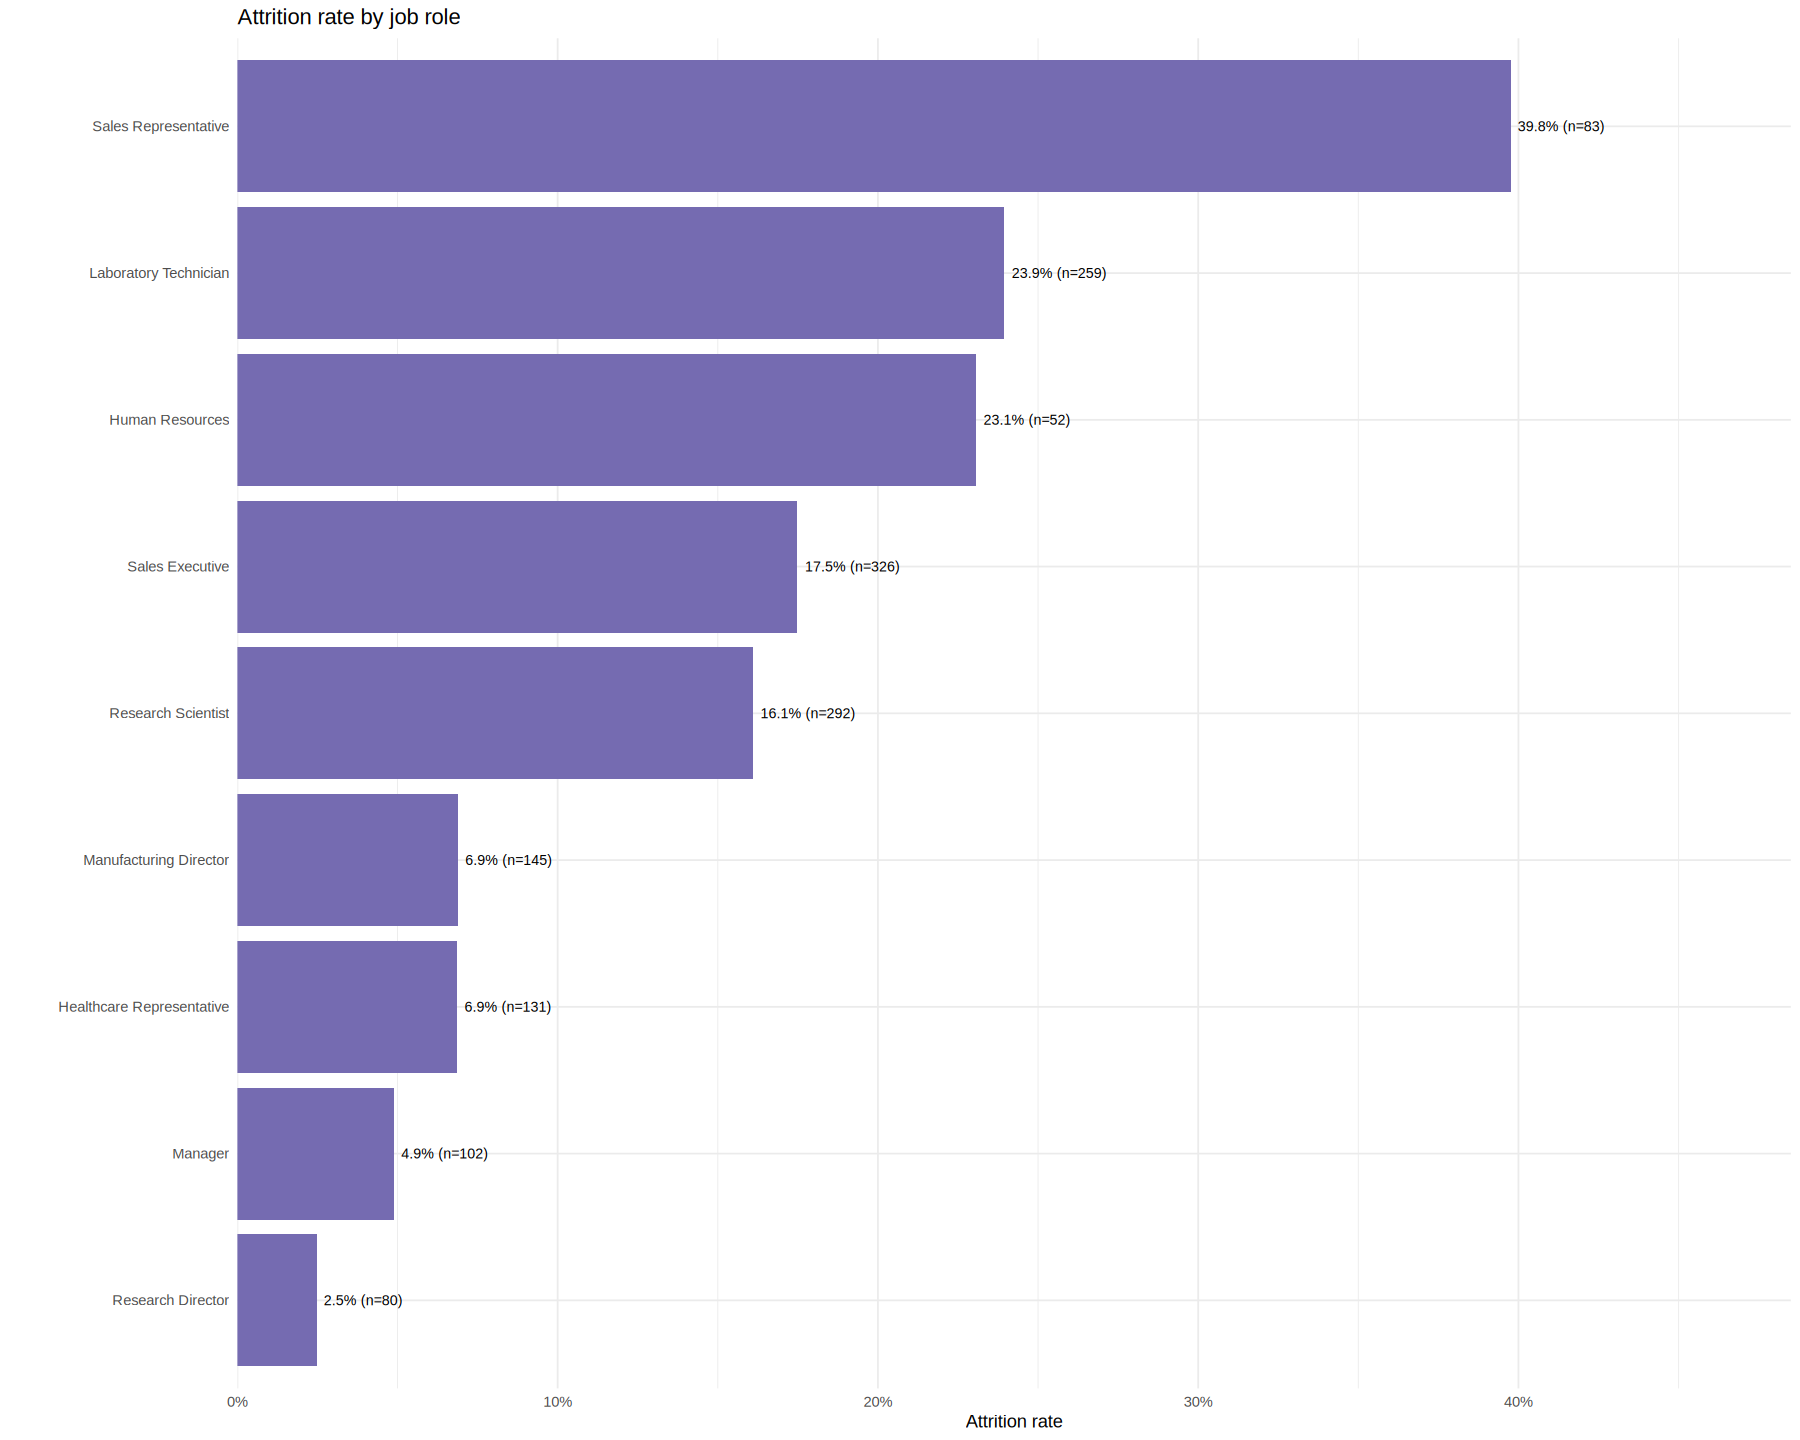

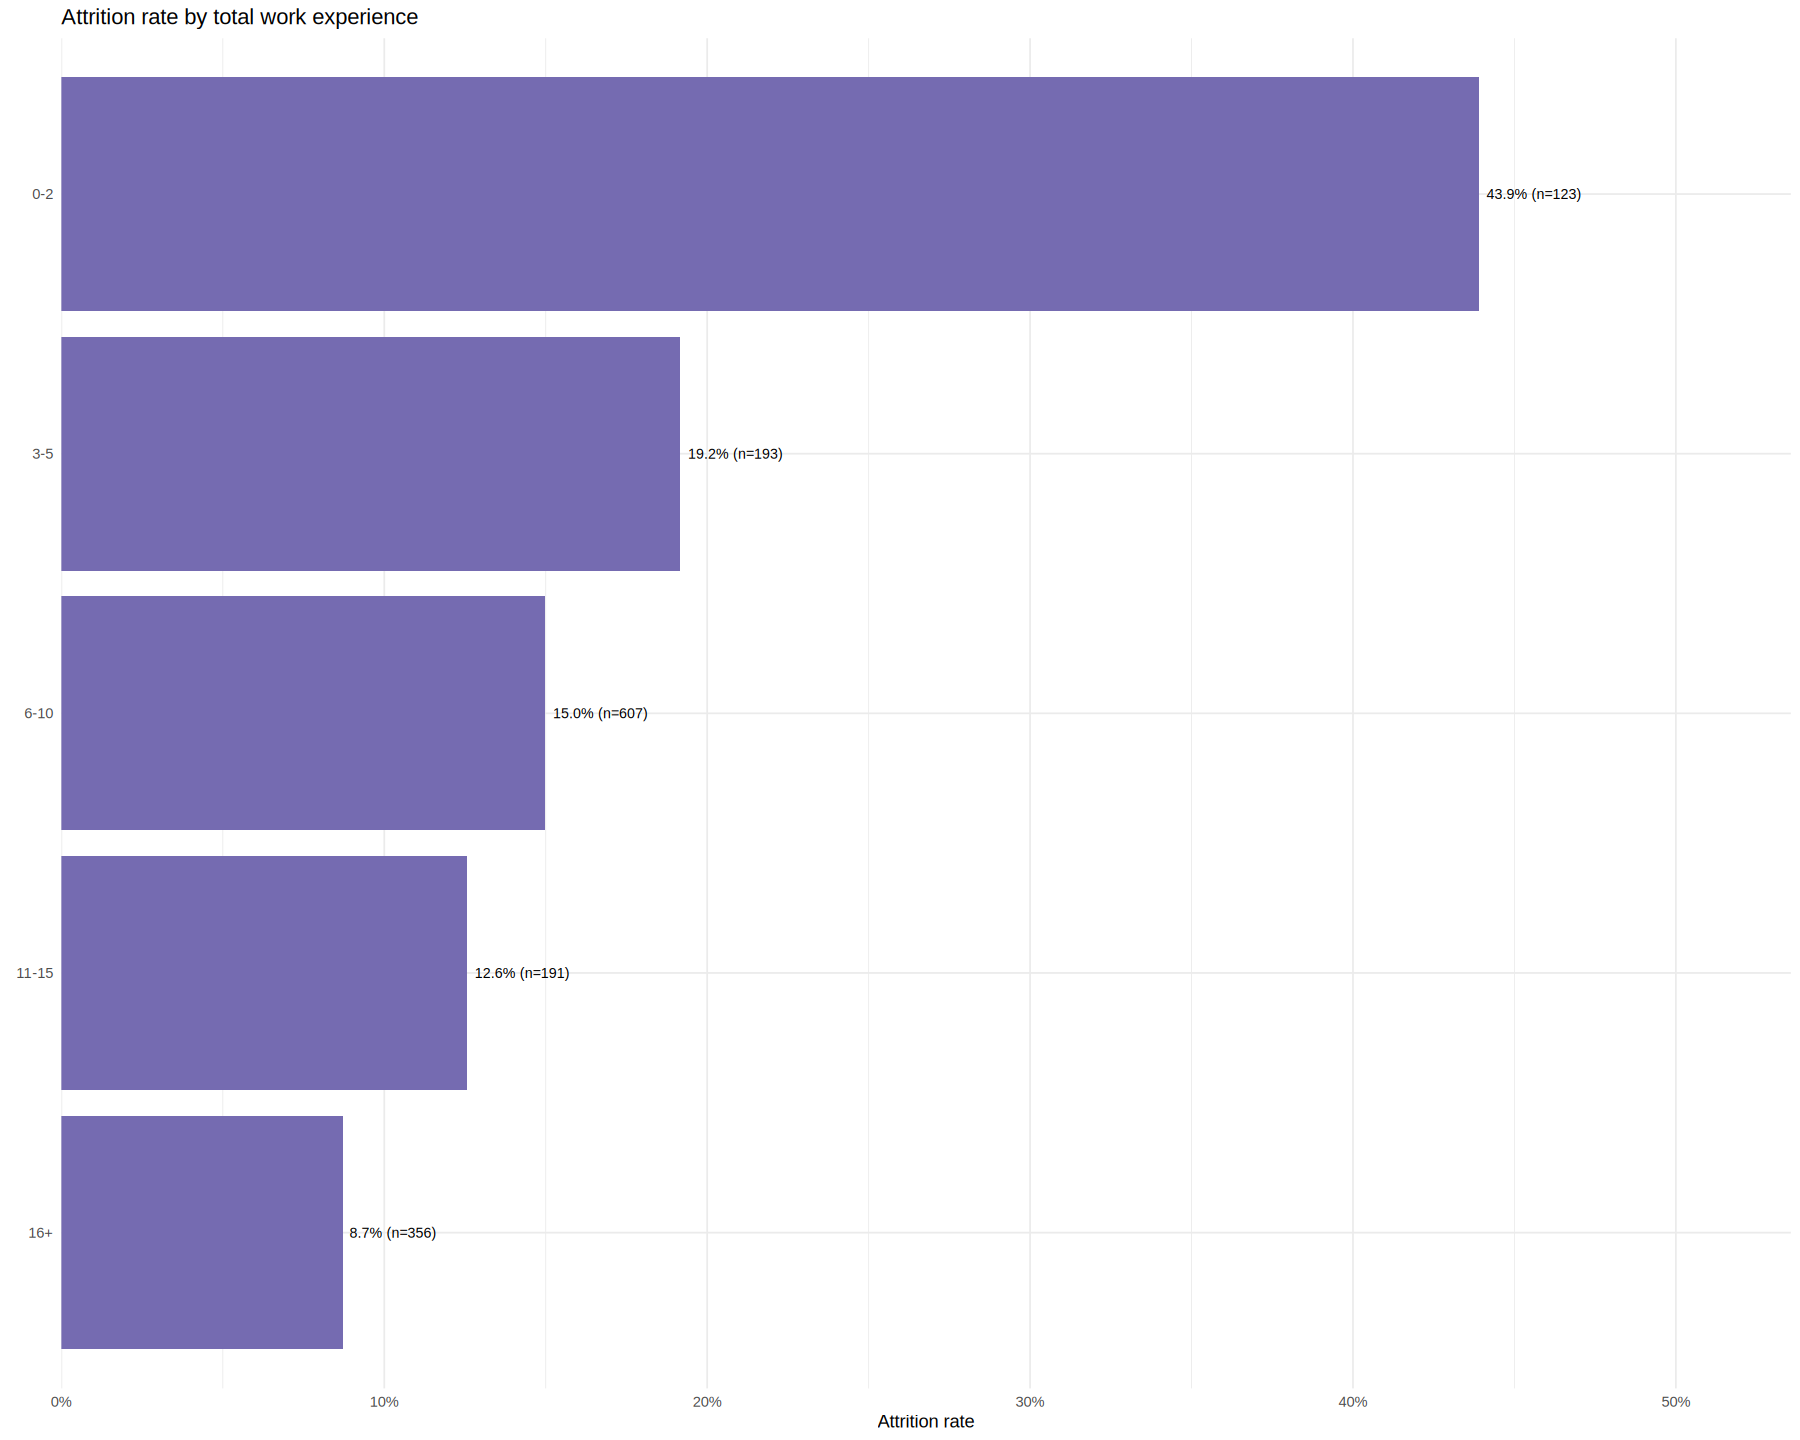

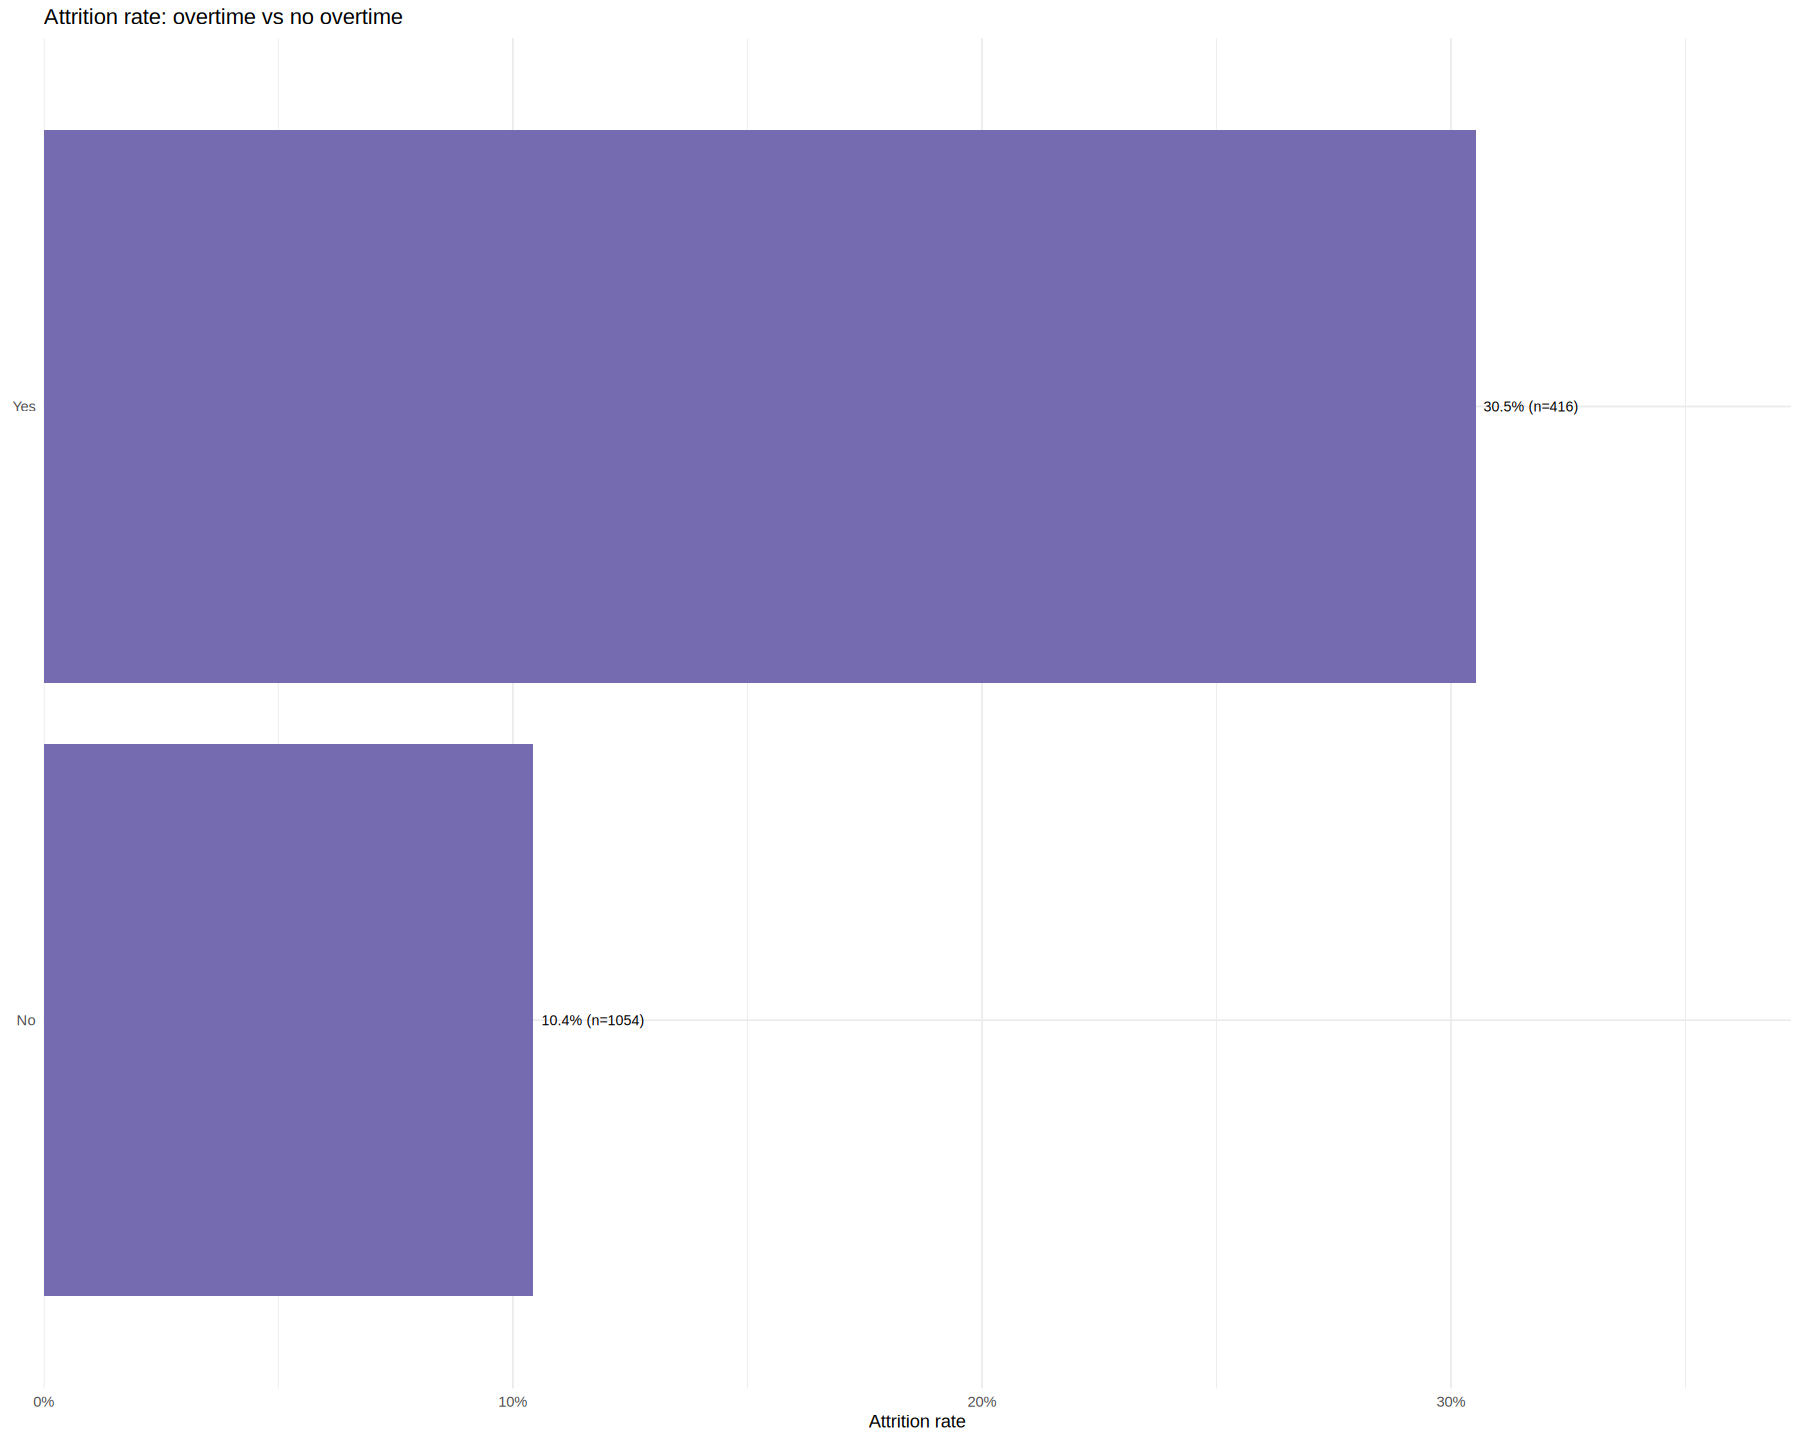

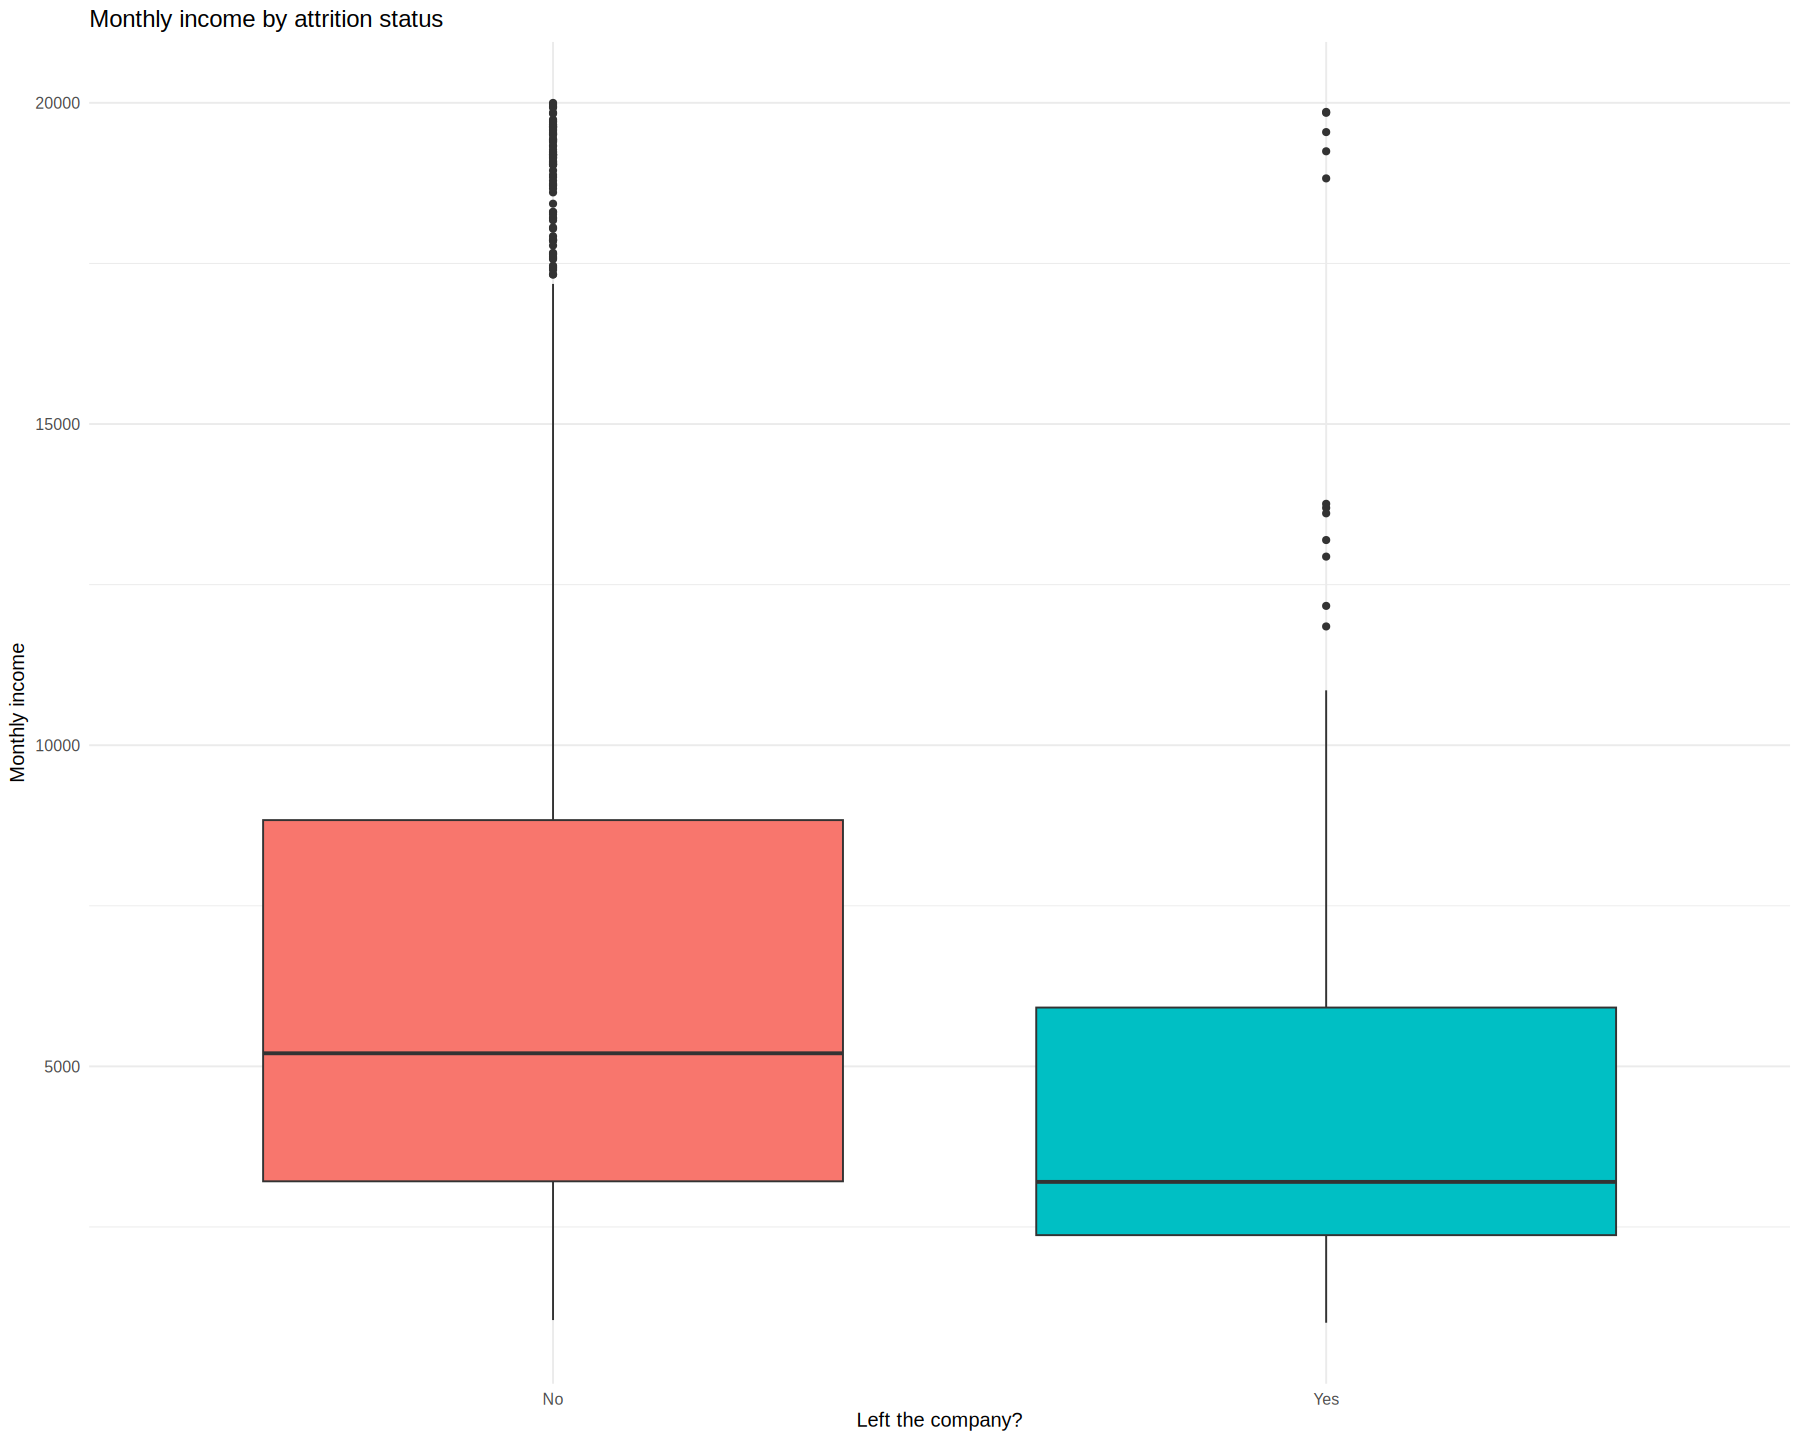

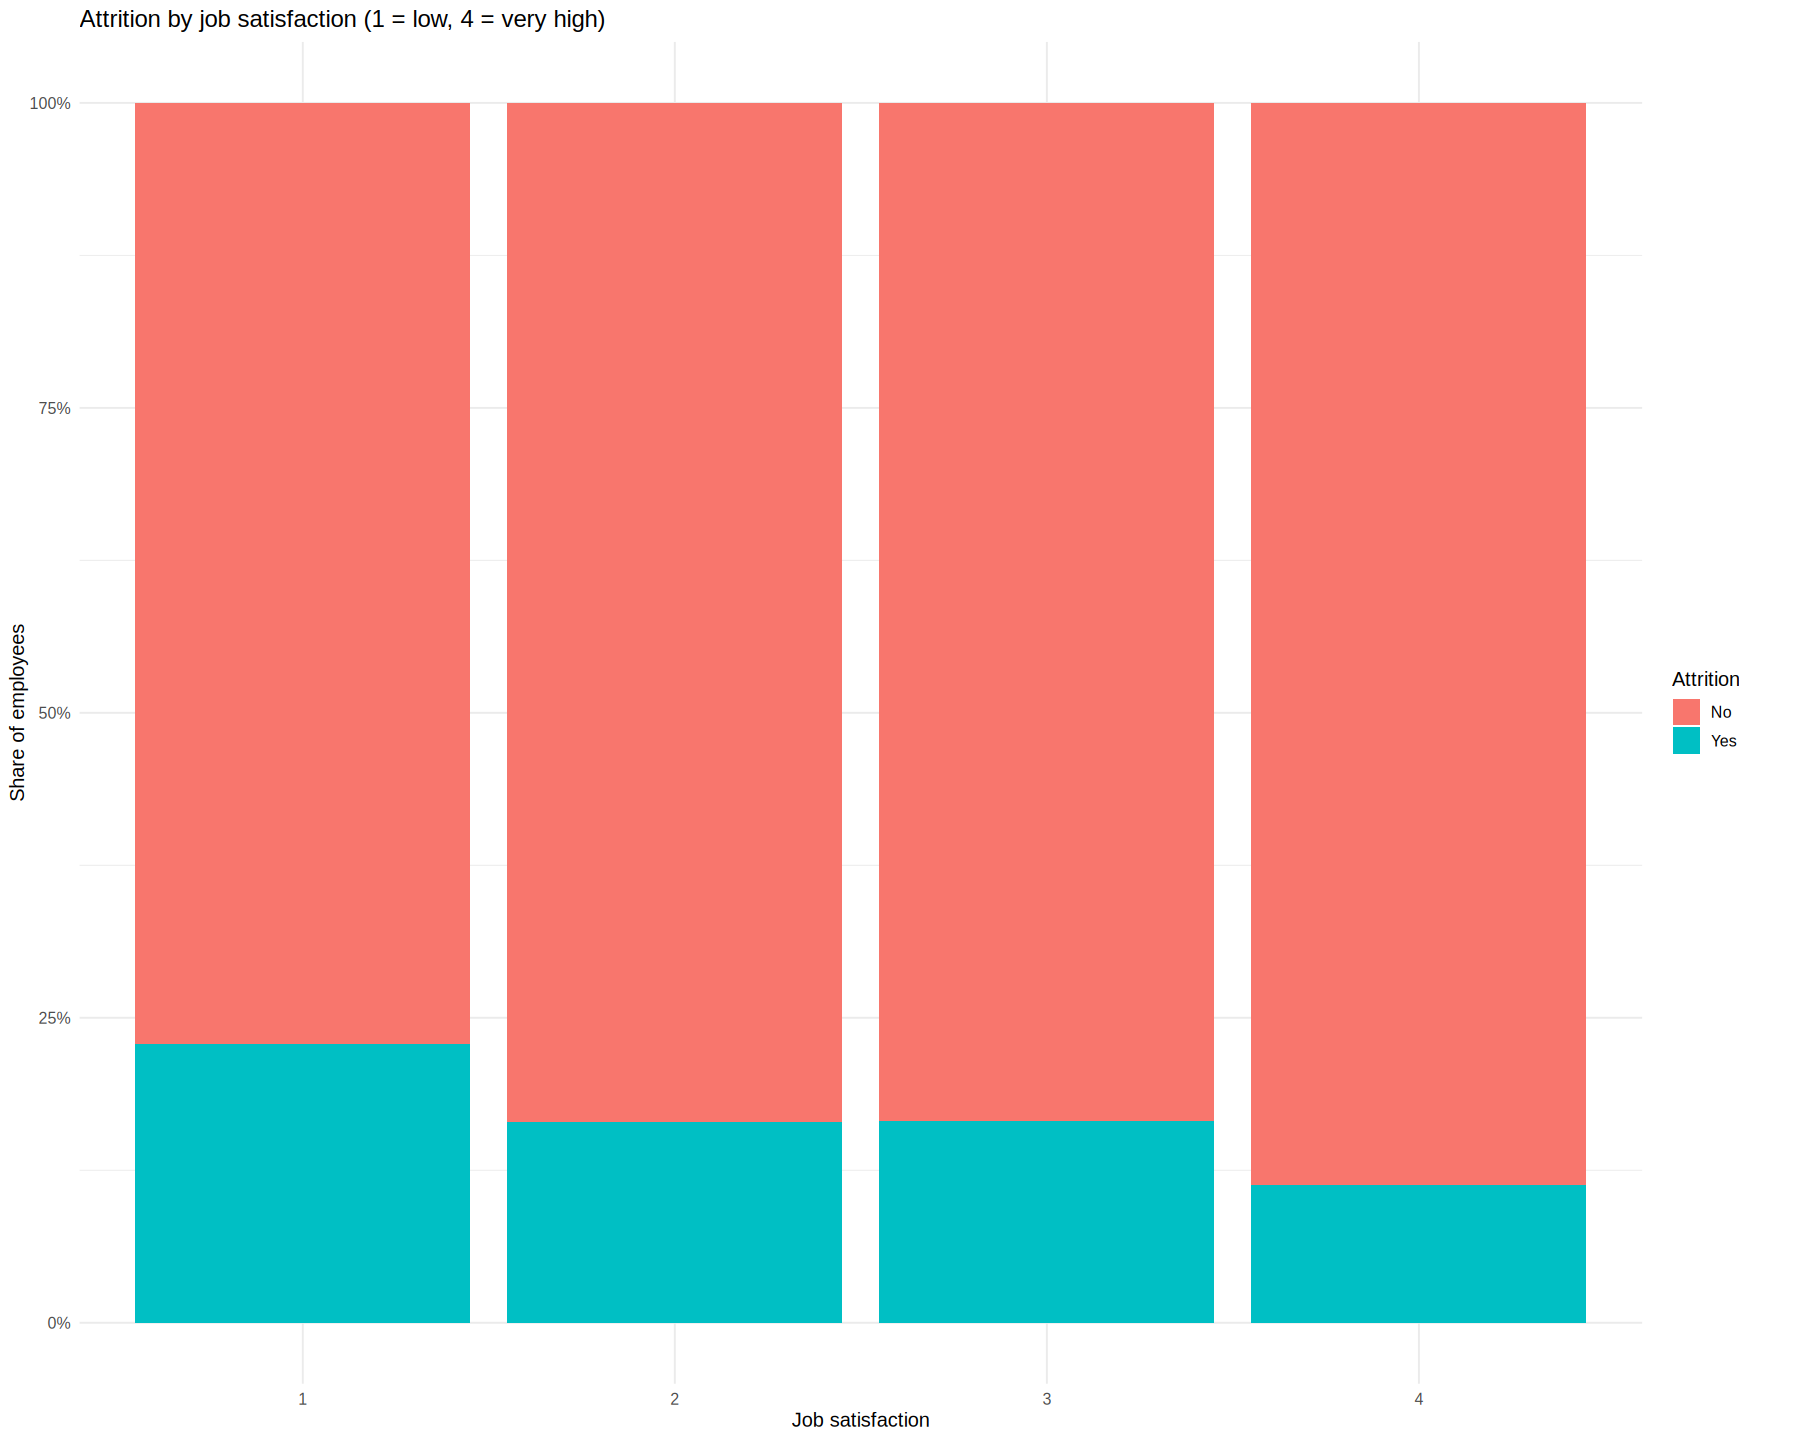

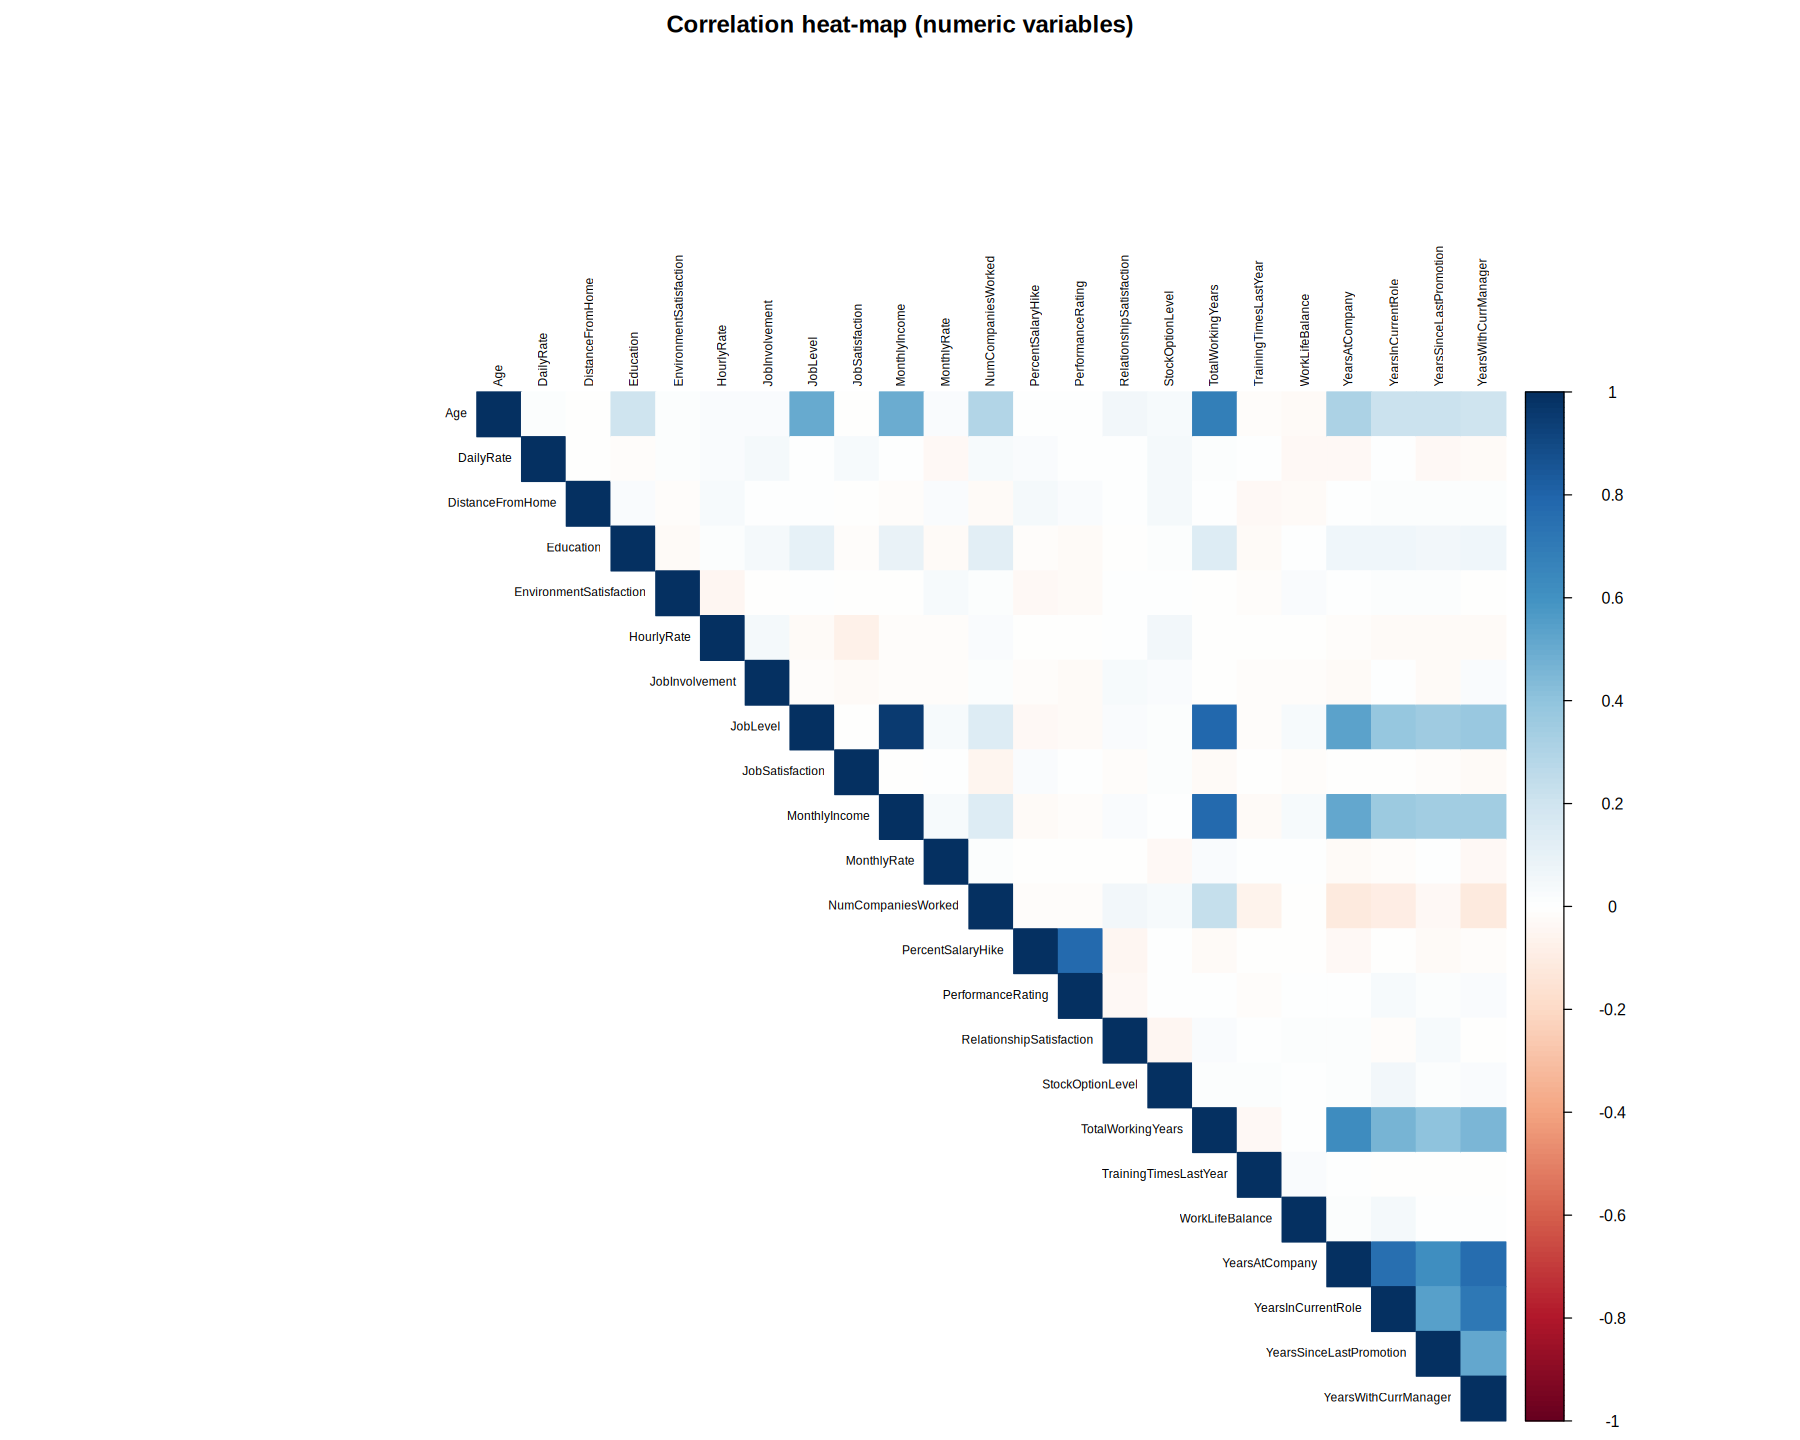

In [ ]:
print(rate_bar(hr_clean, "JobRole", "Attrition", "Yes",
               "Attrition rate by job role", "Attrition rate"))
print(rate_bar(hr_clean, "exp_band", "Attrition", "Yes",
               "Attrition rate by total work experience", "Attrition rate"))
print(rate_bar(hr_clean, "OverTime", "Attrition", "Yes",
               "Attrition rate: overtime vs no overtime", "Attrition rate"))
print(
  ggplot(hr_clean, aes(x = Attrition, y = MonthlyIncome, fill = Attrition)) +
    geom_boxplot(show.legend = FALSE) +
    labs(title = "Monthly income by attrition status", x = "Left the company?", y = "Monthly income")
)
print(
  hr_clean %>%
    count(JobSatisfaction, Attrition) %>%
    group_by(JobSatisfaction) %>% mutate(pct = n / sum(n)) %>%
    ggplot(aes(x = factor(JobSatisfaction), y = pct, fill = Attrition)) +
    geom_col(position = "fill") + scale_y_continuous(labels = percent) +
    labs(title = "Attrition by job satisfaction (1 = low, 4 = very high)",
         x = "Job satisfaction", y = "Share of employees")
)
num_vars <- hr_clean %>% dplyr::select(where(is.numeric))
corrplot(cor(num_vars), method = "color", type = "upper", tl.cex = 0.6, tl.col = "black",
         title = "Correlation heat-map (numeric variables)", mar = c(0, 0, 2, 0))

# 11. Logistic regression model (employee data)

Train: 1103 | Test: 367 

Call:
glm(formula = emp_formula, family = binomial, data = train_e)

Coefficients:
                          Estimate Std. Error z value Pr(>|z|)    
(Intercept)              1.797e+00  6.269e-01   2.867 0.004148 ** 
Age                     -3.442e-02  1.369e-02  -2.515 0.011907 *  
MonthlyIncome           -1.024e-05  6.787e-05  -0.151 0.880064    
OverTimeYes              1.505e+00  1.884e-01   7.984 1.41e-15 ***
JobSatisfaction         -3.555e-01  8.209e-02  -4.330 1.49e-05 ***
DistanceFromHome         3.725e-02  1.084e-02   3.437 0.000589 ***
YearsAtCompany           1.480e-02  2.830e-02   0.523 0.601000    
WorkLifeBalance         -2.799e-01  1.256e-01  -2.229 0.025824 *  
TotalWorkingYears       -9.197e-02  3.085e-02  -2.981 0.002871 ** 
JobLevel                -5.642e-02  2.779e-01  -0.203 0.839092    
NumCompaniesWorked       1.587e-01  3.792e-02   4.186 2.84e-05 ***
EnvironmentSatisfaction -3.663e-01  8.277e-02  -4.426 9.61e-06 ***
---
Signif. codes:  

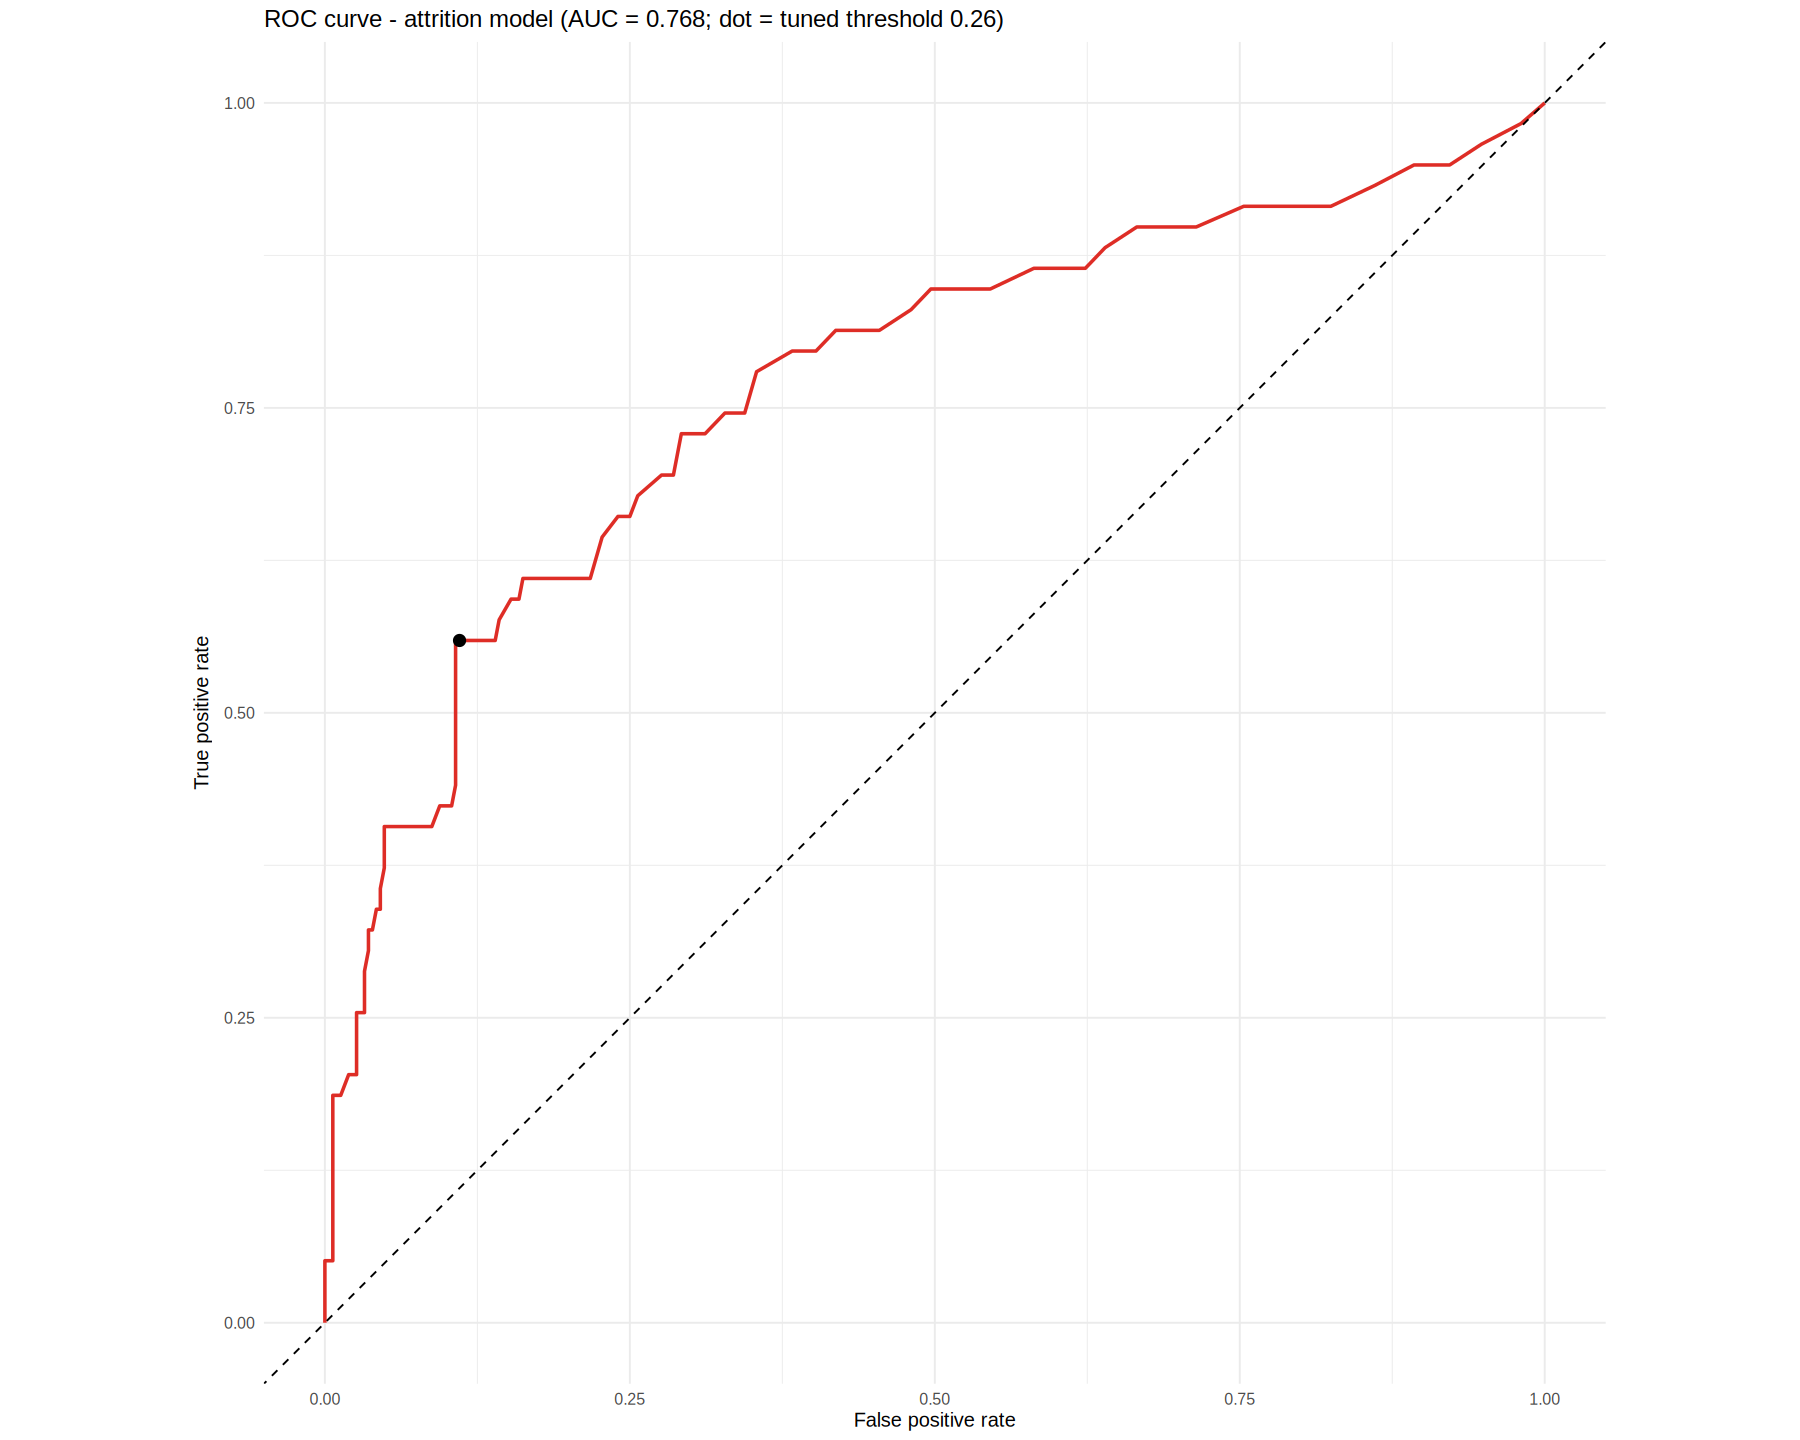

In [ ]:
set.seed(42)
train_idx_e <- as.vector(createDataPartition(hr_clean$Attrition, p = 0.75, list = FALSE))
train_e <- hr_clean[train_idx_e, ]
test_e  <- hr_clean[-train_idx_e, ]
cat("Train:", nrow(train_e), "| Test:", nrow(test_e), "\n")

emp_formula <- Attrition ~ Age + MonthlyIncome + OverTime + JobSatisfaction + DistanceFromHome +
  YearsAtCompany + WorkLifeBalance + TotalWorkingYears + JobLevel + NumCompaniesWorked +
  EnvironmentSatisfaction

log_e <- glm(emp_formula, data = train_e, family = binomial)
print(summary(log_e))

prob_train_e <- predict(log_e, newdata = train_e, type = "response")
thr_e <- youden_threshold(prob_train_e, train_e$Attrition)
test_e$prob <- predict(log_e, newdata = test_e, type = "response")

res_e_default <- eval_model(test_e$prob, test_e$Attrition, 0.5, "Retention - threshold 0.5")
res_e_tuned   <- eval_model(test_e$prob, test_e$Attrition, thr_e, "Retention - tuned threshold")
print(res_e_tuned$cm)
print(rbind(res_e_default$row, res_e_tuned$row))

roc_e <- roc_points(test_e$prob, test_e$Attrition)
op_e  <- roc_e[which.min(abs(roc_e$threshold - thr_e)), ]
print(
  ggplot(roc_e, aes(x = FPR, y = TPR)) + geom_line(colour = "#de2d26", linewidth = 1) +
    geom_abline(linetype = "dashed") +
    geom_point(data = op_e, colour = "black", size = 3) + coord_equal() +
    labs(title = paste0("ROC curve - attrition model (AUC = ", round(res_e_tuned$row$AUC, 3),
                        "; dot = tuned threshold ", thr_e, ")"),
         x = "False positive rate", y = "True positive rate")
)

# 12. LIME - why is a specific employee flagged as high risk?

**Advanced extension:** LIME explains individual predictions locally. For a short review, explain what the plot means rather than describing every implementation detail.


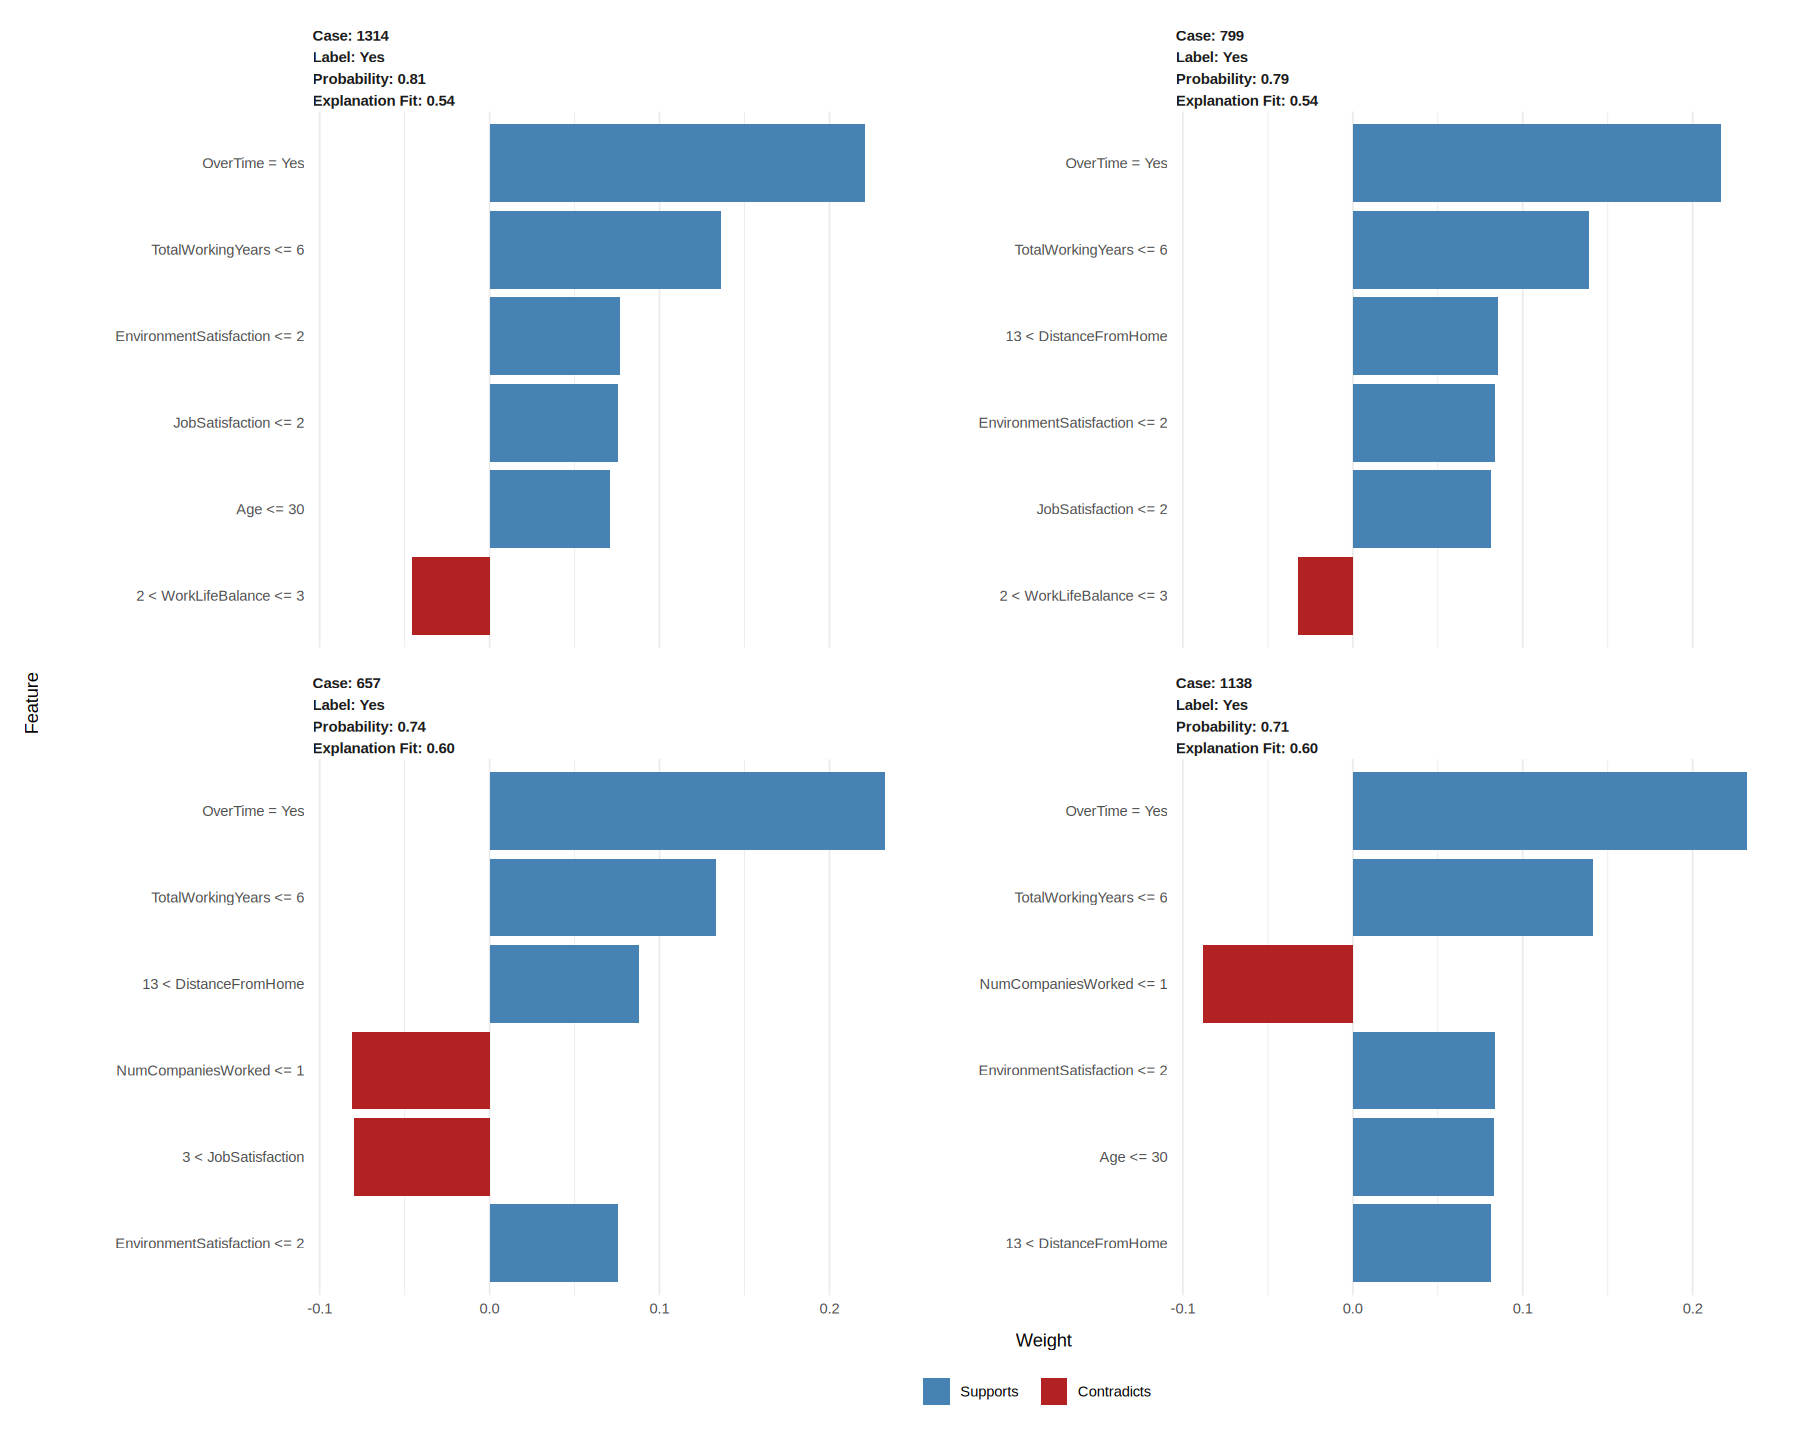

In [ ]:
caret_e <- train(emp_formula, data = train_e, method = "glm", family = "binomial",
                 trControl = trainControl(method = "cv", number = 5, classProbs = TRUE))
pred_cols_e <- all.vars(emp_formula)[-1]
explainer_e <- lime(as.data.frame(train_e[, pred_cols_e]), caret_e)

idx_e <- order(test_e$prob, decreasing = TRUE)[1:4]
explanation_e <- explain(as.data.frame(test_e[idx_e, pred_cols_e]), explainer_e,
                         labels = "Yes", n_features = 6)
print(plot_features(explanation_e))

# 13. Association rules - which workplace conditions occur with attrition?

**Advanced extension:** The rules identify associations in this benchmark dataset. They should not be interpreted as causes or as proof that any individual employee will leave.

Number of attrition rules found: 104 
                                                                                 rule
              {OverTime=Yes,MaritalStatus=Single,DistanceBand=Far} => {Attrition=Yes}
         {OverTime=Yes,MaritalStatus=Single,JobSatBand=JobSat_Med} => {Attrition=Yes}
                       {OverTime=Yes,JobRole=Sales Representative} => {Attrition=Yes}
                 {OverTime=Yes,MaritalStatus=Single,AgeBand=Young} => {Attrition=Yes}
              {OverTime=Yes,Department=Sales,MaritalStatus=Single} => {Attrition=Yes}
 {JobRole=Sales Representative,MaritalStatus=Single,AgeBand=Young} => {Attrition=Yes}
        {OverTime=Yes,JobRole=Laboratory Technician,AgeBand=Young} => {Attrition=Yes}
       {OverTime=Yes,JobRole=Sales Executive,MaritalStatus=Single} => {Attrition=Yes}
     {Department=Sales,MaritalStatus=Single,JobSatBand=JobSat_Med} => {Attrition=Yes}
        {MaritalStatus=Single,AgeBand=Young,JobSatBand=JobSat_Med} => {Attrition=Yes}
    support conf

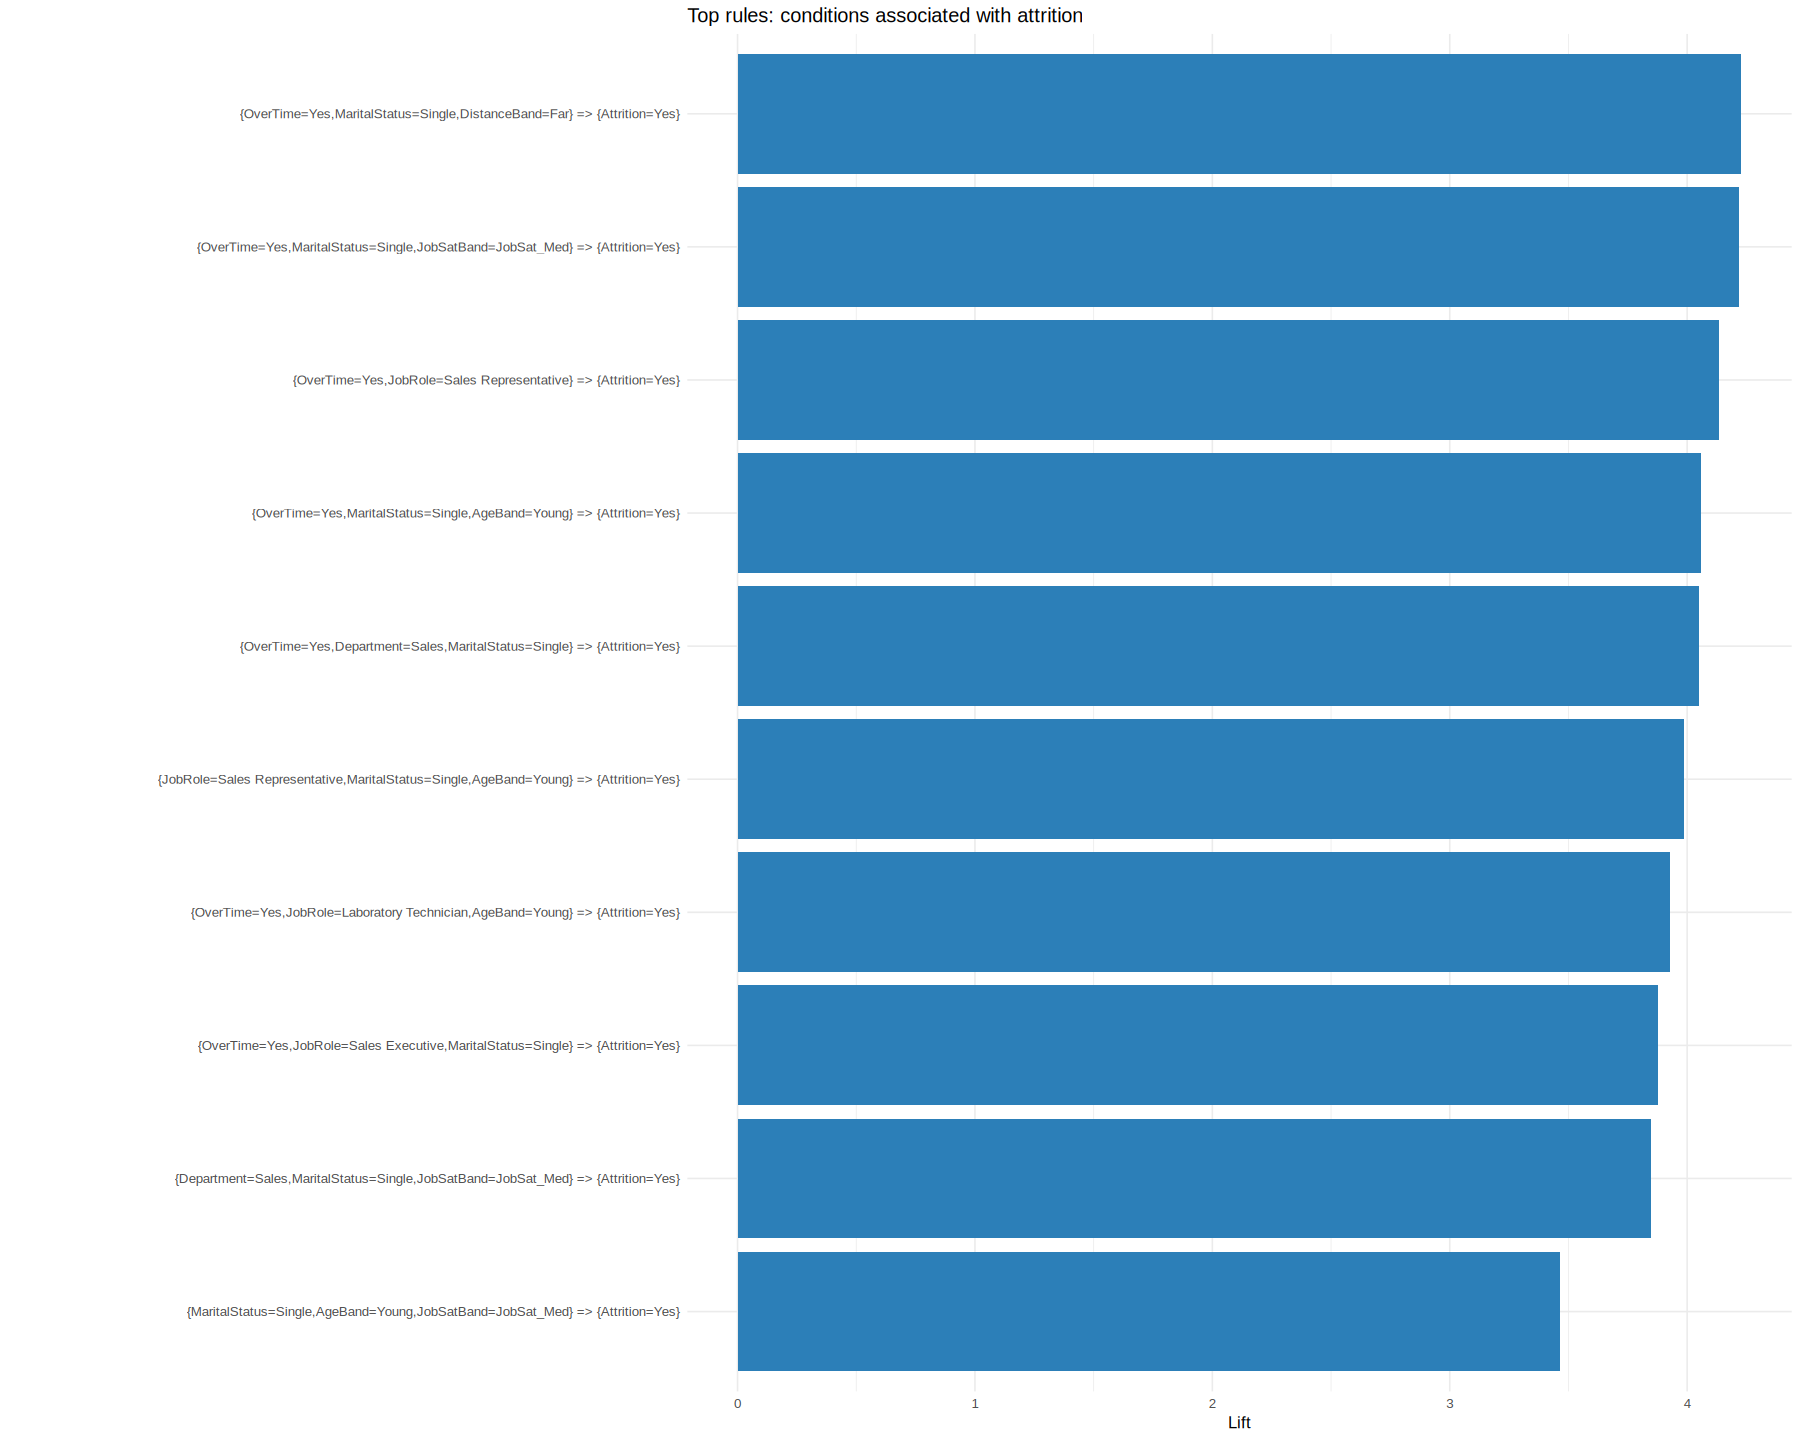

In [ ]:
emp_arules <- hr_clean %>%
  transmute(
    Attrition, OverTime, Department, JobRole, MaritalStatus,
    IncomeBand   = cut(MonthlyIncome, breaks = 3, labels = c("Low_Income", "Mid_Income", "High_Income")),
    AgeBand      = cut(Age, breaks = 3, labels = c("Young", "MidAge", "Senior")),
    TenureBand   = cut(YearsAtCompany, breaks = 3, labels = c("Short_Tenure", "Mid_Tenure", "Long_Tenure")),
    DistanceBand = cut(DistanceFromHome, breaks = 3, labels = c("Near", "Moderate", "Far")),
    JobSatBand   = factor(JobSatisfaction, levels = 1:4,
                          labels = c("JobSat_Low", "JobSat_Med", "JobSat_High", "JobSat_VeryHigh")),
    WLBBand      = factor(WorkLifeBalance, levels = 1:4,
                          labels = c("WLB_Bad", "WLB_Good", "WLB_Better", "WLB_Best"))
  ) %>%
  mutate(across(everything(), as.factor))

trans_e <- as(emp_arules, "transactions")

rules_attr <- mine_rules(trans_e, "Attrition=Yes", supp = 0.01, conf = 0.30)
cat("Number of attrition rules found:", length(rules_attr), "\n")
show_rules(rules_attr, "Top rules: conditions associated with attrition", "attrition_association_rules.csv")

# PART C - TALENT LIFECYCLE VIEW: candidate stability proxy vs employee retention

# 14. Exploratory comparison by experience band

The two datasets describe different people. This chart compares group-level rates only; it does not track the same candidates from application to employment and should not be treated as a direct or causal lifecycle prediction.

# A tibble: 10 × 3
   exp_band  rate measure                                     
   <ord>    <dbl> <chr>                                       
 1 0-2      0.616 Candidates: not seeking a job change (proxy)
 2 3-5      0.678 Candidates: not seeking a job change (proxy)
 3 6-10     0.747 Candidates: not seeking a job change (proxy)
 4 11-15    0.809 Candidates: not seeking a job change (proxy)
 5 16+      0.844 Candidates: not seeking a job change (proxy)
 6 0-2      0.561 Employees: stay (1 - attrition)             
 7 3-5      0.808 Employees: stay (1 - attrition)             
 8 6-10     0.85  Employees: stay (1 - attrition)             
 9 11-15    0.874 Employees: stay (1 - attrition)             
10 16+      0.913 Employees: stay (1 - attrition)             


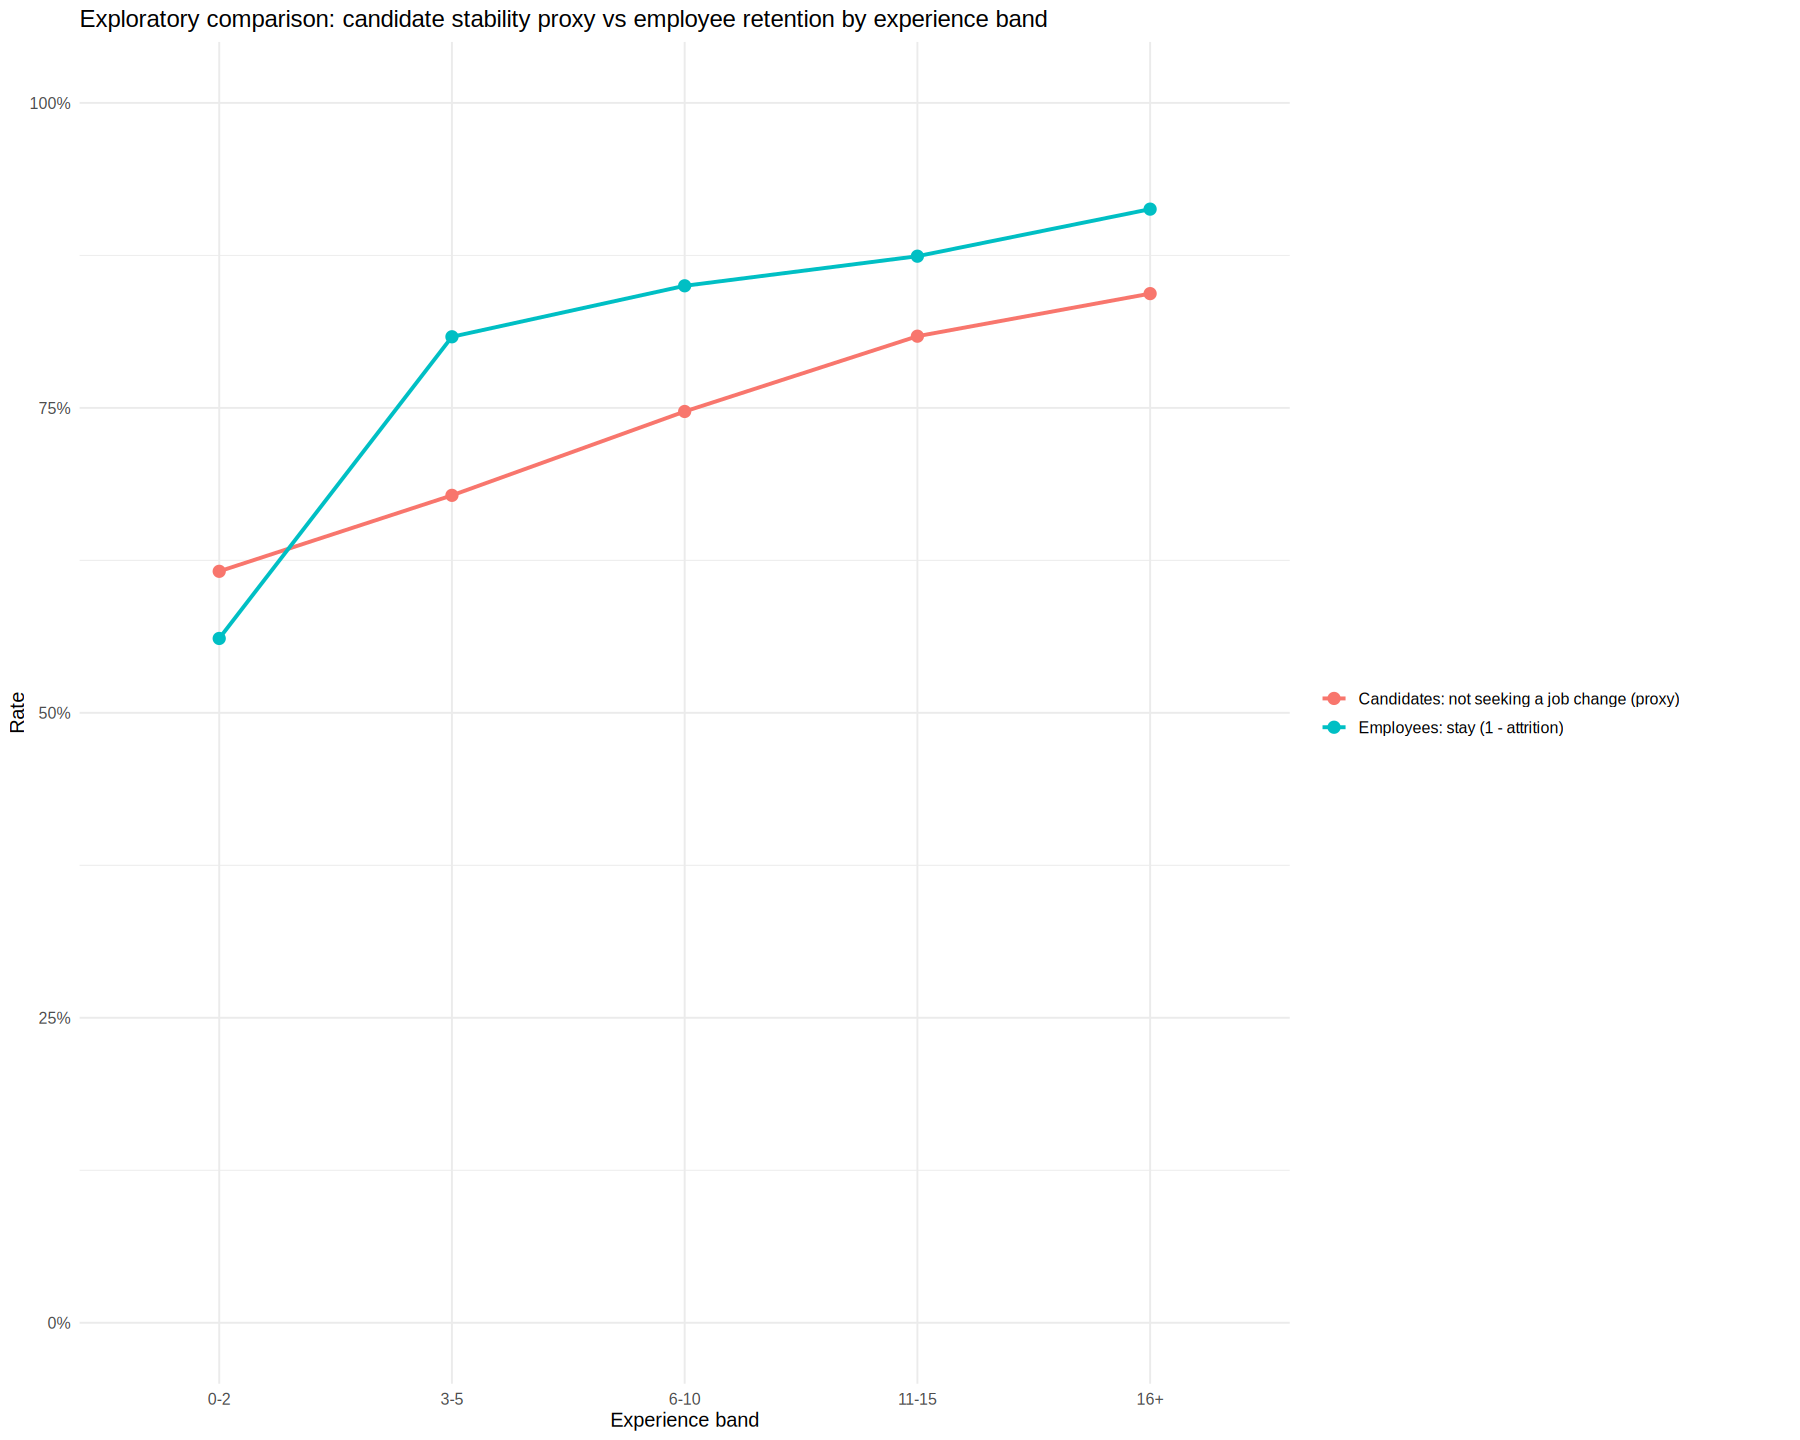

In [ ]:
join_by_exp <- cand_clean %>%
  group_by(exp_band) %>%
  summarise(rate = mean(Likely_Join == "Yes"), .groups = "drop") %>%
  mutate(measure = "Candidates: not seeking a job change (proxy)")

stay_by_exp <- hr_clean %>%
  group_by(exp_band) %>%
  summarise(rate = mean(Attrition == "No"), .groups = "drop") %>%
  mutate(measure = "Employees: stay (1 - attrition)")

lifecycle_tbl <- bind_rows(join_by_exp, stay_by_exp) %>% mutate(rate = round(rate, 3))
print(lifecycle_tbl)

print(
  bind_rows(join_by_exp, stay_by_exp) %>%
    ggplot(aes(x = exp_band, y = rate, colour = measure, group = measure)) +
    geom_line(linewidth = 1.1) + geom_point(size = 3) +
    scale_y_continuous(labels = percent, limits = c(0, 1)) +
    labs(title = "Exploratory comparison: candidate stability proxy vs employee retention by experience band",
         x = "Experience band", y = "Rate", colour = NULL)
)

# 15. Summary of results

In [ ]:
metrics <- rbind(res_c_default$row, res_c_tuned$row, res_e_default$row, res_e_tuned$row)
metrics[, -1] <- round(metrics[, -1], 3)
print(metrics)
write.csv(metrics, "model_metrics.csv", row.names = FALSE)

cat("\n================ SUMMARY ================\n")
cat("Candidates analysed         :", nrow(cand_clean), "\n")
cat("Not-seeking-change proxy rate :", percent(mean(cand_clean$Likely_Join == "Yes"), accuracy = 0.1), "\n")
cat("Candidate proxy model AUC            :", round(res_c_tuned$row$AUC, 3), "\n")
cat("Employees analysed          :", nrow(hr_clean), "\n")
cat("Overall attrition rate      :", percent(mean(hr_clean$Attrition == "Yes"), accuracy = 0.1), "\n")
cat("Attrition model AUC         :", round(res_e_tuned$row$AUC, 3), "\n")
cat("Files written: top_candidates_shortlist.csv, candidate_join_rules.csv, candidate_notjoin_rules.csv,\n               attrition_association_rules.csv, model_metrics.csv\n")
cat("=========================================\n")

                              Model Threshold Accuracy Recall Specificity
1   Candidate proxy - threshold 0.5      0.50    0.767  0.932       0.271
2 Candidate proxy - tuned threshold      0.76    0.726  0.721       0.744
3         Retention - threshold 0.5      0.50    0.850  0.203       0.974
4       Retention - tuned threshold      0.26    0.837  0.559       0.890
  Precision   AUC
1     0.794 0.770
2     0.894 0.770
3     0.600 0.768
4     0.493 0.768

================ SUMMARY ================
Candidates analysed         : 19158 
Not-seeking-change proxy rate : 75.1% 
Candidate proxy model AUC            : 0.77 
Employees analysed          : 1470 
Overall attrition rate      : 16.1% 
Attrition model AUC         : 0.768 
Files written: top_candidates_shortlist.csv, candidate_join_rules.csv, candidate_notjoin_rules.csv,
               attrition_association_rules.csv, model_metrics.csv
